# Round 5: a class-anchored contrast, test-time re-scoring and headroom

mAP ranks *images* within each class. The contrastive losses of
rounds 1-4 ranked other things: images by similarity to each other
(rounds 1-3) or the classes of one image (round 4). Round 5 adds a
contrastive loss that ranks exactly what AP measures, keeps the
relation types at its core, and asks how much mAP is at stake.

1. **Relation-typed class-anchored contrast (ours).** Each class
   vector (it starts at the class-name text embedding) is an anchor;
   the training images with that class are its positives and every
   other training image is a negative. A negative image is weighted
   1 + alpha x rho, where rho is the relation value of its most
   confusable label for that class (1, 0.5, 0.25 or 0). This is the
   text-to-image half of CLIP's own training loss, with relation-typed
   negatives, and it gives every class the same weight. Control: the
   same loss with uniform weights (alpha = 0).
2. **Margins + class-anchored contrast (ours).** The round-4 margins
   (m = 1, tail and medium classes) together with the chosen
   class-anchored contrast.
3. **Relation-typed re-scoring at test time (ours).** A class's score
   is lowered on images where a related class scores higher, with one
   strength per relation type, chosen by cross-validation (strength 0
   = no re-scoring). Either the blended score is re-scored, or only the
   zero-shot part of the blend, with the trained classifier deciding
   which class is stronger.
4. **Headroom.** On the test scores of TA and of the best system:
   how much AP each class would gain if the images of its related
   classes were scored like its unrelated negatives (with the same
   number of objects). This is the most any fix of related-class
   confusion could give.

Everything else is as in rounds 3-4 (CLIP-initialised classifier,
zero-shot blend, all 1,909 training images, 5-fold cross-validation
scored by (overall mAP + tail mAP) / 2, 10 seeds). Saved runs of
rounds 3-4 are reused, so only the new variants are trained.

**Decision rule, fixed before running (as in rounds 3-4).** A
relation-typed variant *works* better than a method if (a) tail AP is
higher, with a 95% interval above zero and a higher tail mAP in at
least 7 of 10 seeds; (b) the related-class false-positive gap is lower
under both controls; (c) head AP drops by at most 1 point. PARTLY:
(a) or (b), with (c). Key tests: class-anchored RTN against its
uniform version and against TA; the best RTN system (with re-scoring)
against TA. **Round 5 is exploratory**: a gain must be confirmed on a
second dataset with every setting fixed in advance.

## Step 0: setup

In [1]:
import hashlib
import importlib
import itertools
import json
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from scipy import sparse

if not os.path.exists("context_reliance_check.py"):
    raise SystemExit("Put context_reliance_check.py in the same folder "
                     "as this notebook.")
import context_reliance_check as crc
importlib.reload(crc)
if not hasattr(crc, "related_labels"):
    raise SystemExit("context_reliance_check.py is an older version. "
                     "Replace it with the latest one.")
pd.set_option("display.max_colwidth", None)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"numpy {np.__version__}, pandas {pd.__version__}, "
      f"torch {torch.__version__}")
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"Device: {props.name} ({props.total_memory / 2**30:.1f} GB)")
else:
    print(f"Device: CPU (this PyTorch build has CUDA: {torch.version.cuda})")

numpy 2.5.4, pandas 3.1.0, torch 2.11.0+cu130
Device: NVIDIA GeForce RTX 4070 Laptop GPU (8.0 GB)


## Step 1: settings

In [2]:
DATA = "coco_mlt"
RUNS = os.path.join(DATA, "round3")   # saved runs, shared with rounds 3 and 4
OUT = os.path.join(DATA, "round5")
SEEDS = list(range(42, 52))   # 10 seeds for the final models
CV_FOLDS, FOLD_SEED, CV_RUN_SEED = 5, 0, 42
RELATED_PCT = 5               # related = top 5% most text-similar labels
BOOTSTRAP = 10000
RETRAIN = False               # True reruns everything, ignoring saved runs
ALLOW_CPU = False             # True lets the full run go ahead without a GPU
QUICK_TEST = False            # True = tiny run to test the code only
PROMPT_ENSEMBLE = "auto"      # "auto": use it if it scores better on the
                              # training images; True / False to force
MODEL_CACHE = "model_cache"   # folder holding ViT-B-16.pt

# Fixed settings of the CLIP-initialised classifier (TA)
TA_FIXED = dict(hidden=512, dropout=0.1, scale=20.0, lr=1e-3, wd=1e-4,
                batch=64, tau=0.1)
# Rounds 3-4 (their saved runs are reused):
GRID_TA = [dict(loss=l, epochs=e, cls_lr=c) for l in ("BCE", "ASL")
           for e in (10, 30, 90) for c in (0.0, 0.1, 1.0)]   # cls_lr 0 = text vectors fixed
GRID_RTN = [dict(lam=lam, q=q, alpha=a, target=t)
            for lam in (0.02, 0.05, 0.15) for q in (0.0, 0.5)
            for a in (2.0, 4.0, 8.0) for t in ("tail+medium", "all")]
GRID_CC_RTN = [dict(cc=c, cc_alpha=a, q=q, target=t)
               for c in (0.1, 0.3, 1.0) for q in (0.0, 0.5)
               for a in (2.0, 4.0, 8.0) for t in ("tail+medium", "all")]
GRID_MARGIN = [dict(margin=m, target=t) for m in (0.5, 1.0, 2.0, 4.0)
               for t in ("tail+medium", "all")]
# Round 5: class-anchored contrast (ca = its weight; ca_alpha = relation weight)
GRID_CA_UNI = [dict(ca=c, ca_alpha=0.0) for c in (0.1, 0.3, 1.0, 3.0)]
GRID_CA_RTN = [dict(ca=c, ca_alpha=a, ca_target=t) for c in (0.1, 0.3, 1.0, 3.0)
               for a in (2.0, 4.0, 8.0) for t in ("tail+medium", "all")]
# Round 5: re-scoring strengths per relation value (R = 1, 0.5, 0.25)
GAMMAS = [0.0, 0.25, 0.5, 1.0, 2.0]
RS_VARIANTS = ("blend", "zero-shot")
HEADROOM_DRAWS = 5
BETAS = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0]   # zero-shot ensemble weights
LP_SETTINGS = {"BCE": (1e-3, 200), "ASL": (1e-3, 50)}   # context-check notebook

if QUICK_TEST:
    SEEDS, CV_FOLDS, BOOTSTRAP, HEADROOM_DRAWS = [42, 43], 2, 200, 2
    GRID_TA = [dict(loss="ASL", epochs=2, cls_lr=0.1), dict(loss="ASL", epochs=2, cls_lr=0.0)]
    GRID_RTN = [dict(lam=0.15, q=0.5, alpha=4.0, target="tail+medium")]
    LP_SETTINGS = {"BCE": (1e-3, 2), "ASL": (1e-3, 2)}
    GRID_CC_RTN = [dict(cc=0.3, cc_alpha=4.0, q=0.5, target="tail+medium")]
    GRID_MARGIN = [dict(margin=1.0, target="tail+medium")]
    GRID_CA_UNI = [dict(ca=1.0, ca_alpha=0.0)]
    GRID_CA_RTN = [dict(ca=1.0, ca_alpha=4.0, ca_target="all")]
    GAMMAS = [0.0, 1.0]

VARIANTS = [   # key, name
    ("zs", "Zero-shot CLIP (no training)"),
    ("lp_bce", "Linear probe, BCE"),
    ("lp_asl", "Linear probe, ASL"),
    ("ta", "CLIP-initialised adapter (TA)"),
    ("rtn", "TA + RTN on image embeddings (round 3)"),
    ("cc_rtn", "TA + relation-typed class contrast (round 4)"),
    ("margin", "TA + relation-typed margins (round 4)"),
    ("ca_uni", "TA + class-anchored contrast, uniform weights"),
    ("ca_rtn", "TA + relation-typed class-anchored contrast (ours)"),
    ("ca_margin", "TA + margins + relation-typed class-anchored contrast (ours)"),
    ("ta_rs", "TA + relation-typed re-scoring (ours)"),
    ("full", "Best RTN model + re-scoring (ours)"),
]
NAME = dict(VARIANTS)
SHORT = {"zs": "Zero-shot", "lp_bce": "LP-BCE", "lp_asl": "LP-ASL", "ta": "TA",
         "rtn": "TA + image RTN", "cc_rtn": "TA + class RTN", "margin": "TA + RTN margins",
         "ca_uni": "TA + anchored uniform", "ca_rtn": "TA + anchored RTN",
         "ca_margin": "TA + margins + anchored RTN", "ta_rs": "TA + re-scoring",
         "full": "Best RTN + re-scoring"}
TRAINED = ["lp_bce", "lp_asl", "ta", "rtn", "cc_rtn", "margin", "ca_uni", "ca_rtn",
           "ca_margin"]
CODE_VERSION = "round3-2026-11-02"   # unchanged, so saved runs stay valid
for sub in ("cv", "final"):
    os.makedirs(os.path.join(RUNS, sub), exist_ok=True)
os.makedirs(OUT, exist_ok=True)
if DEVICE == "cpu" and not (QUICK_TEST or ALLOW_CPU):
    raise SystemExit(
        "No GPU is visible to this notebook; the full run would take hours "
        "on the CPU. Pick the kernel you used for the earlier notebooks "
        "(Kernel > Change kernel), or set ALLOW_CPU = True.")
print(f"New settings to cross-validate: {len(GRID_CA_UNI)} + {len(GRID_CA_RTN)} + 1 "
      f"({CV_FOLDS} folds), then {len(SEEDS)} seeds per method; rounds 3-4 settings "
      f"are reused. Re-scoring: {len(GAMMAS) ** 3 - 1} strength combinations x "
      f"{len(RS_VARIANTS)} variants x 2 class sets, on saved predictions.")

New settings to cross-validate: 4 + 24 + 1 (5 folds), then 10 seeds per method; rounds 3-4 settings are reused. Re-scoring: 124 strength combinations x 2 variants x 2 class sets, on saved predictions.


## Step 2: method code

Writes `rtn_clip_method.py` next to this notebook: rounds 3-4 code plus
the class-anchored contrast, re-scoring and headroom functions. Settings
of rounds 3-4 behave exactly as before, so their saved runs stay valid.

In [3]:
%%writefile rtn_clip_method.py
"""Round 3: relation-typed negatives (RTN) on a CLIP-initialised classifier.

Everything works on frozen CLIP ViT-B/16 features (L2-normalised image
embeddings) and the CLIP text embeddings of the class names, so one training
run takes seconds.

Model ("TA"): a residual adapter that starts as the identity, followed by a
cosine classifier whose class vectors start at the class-name text
embeddings. At initialisation it ranks images exactly as zero-shot CLIP does.
Loss: classification (BCE or ASL) + lambda x label-wise supervised
contrastive loss (MulSupCon's anchors: one per image and label) computed
against every training image, with relation-typed weights on the negatives.

Round 4 adds two classifier-level forms of RTN: a class contrast (each
positive label of an image against the other classes' vectors, related
classes weighted more) and relation-typed margins in the classification
loss. Settings without them behave exactly as in round 3.

Round 5 adds (i) a class-anchored contrast: each class vector is an anchor,
its training images are the positives and every other training image is a
negative, with relation-typed weights on the negatives, so the loss ranks
images within each class (what AP measures); (ii) relation-typed re-scoring
at test time; (iii) a headroom (oracle) analysis. Settings without them
behave exactly as in rounds 3 and 4.
"""
import math

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ------------------------------------------------------------- data utils ----
def iterative_split(Y, test_frac, seed):
    """Iterative stratification (Sechidis et al., 2011), two parts.
    Identical to round 1's function: 0 = fit, 1 = dev."""
    return iterative_folds(Y, None, seed, fracs=[1.0 - test_frac, test_frac])


def iterative_folds(Y, k, seed, fracs=None):
    """Iterative stratification into k folds of equal size (or the given
    fractions). Returns the fold index of every row."""
    rng = np.random.default_rng(seed)
    Y = np.asarray(Y, dtype=bool)
    n = Y.shape[0]
    frac = np.asarray(fracs if fracs is not None else [1.0 / k] * k, dtype=float)
    desired = frac * n
    desired_label = np.outer(frac, Y.sum(0)).astype(float)
    remaining = np.ones(n, dtype=bool)
    assign = -np.ones(n, dtype=int)
    while True:
        rem = Y[remaining].sum(0)
        if rem.sum() == 0:
            break
        label = int(np.argmin(np.where(rem > 0, rem, np.iinfo(np.int64).max)))
        idx = np.flatnonzero(remaining & Y[:, label])
        rng.shuffle(idx)
        for i in idx:
            d = desired_label[:, label]
            cand = np.flatnonzero(d == d.max())
            if cand.size > 1:
                ds = desired[cand]
                cand = cand[ds == ds.max()]
            s = int(rng.choice(cand)) if cand.size > 1 else int(cand[0])
            assign[i] = s
            remaining[i] = False
            desired_label[s] -= Y[i]
            desired[s] -= 1
    for i in np.flatnonzero(remaining):          # images without labels
        s = int(np.argmax(desired))
        assign[i] = s
        desired[s] -= 1
    return assign


def relation_masks(sim, shared, n_train, n_images, related_fn, pct,
                   min_shared=2, lift_min=2.0):
    """Relation types from training labels only (same as rounds 1 and 2):
    related & seen together, related & never together, informative companion,
    and 'any companion' (seen together at least once)."""
    L = sim.shape[0]
    rel_seen = np.zeros((L, L), bool)
    rel_never = np.zeros((L, L), bool)
    informative = np.zeros((L, L), bool)
    companion = np.zeros((L, L), bool)
    base = n_train / n_images
    for t in range(L):
        related = related_fn(sim[t], t, pct)
        for c in range(L):
            if c == t:
                continue
            k = shared[t, c]
            if k >= 1:
                companion[t, c] = True
            if related[c]:
                (rel_seen if k >= 1 else rel_never)[t, c] = True
            elif k >= min_shared and n_train[t] and base[c]:
                if (k / n_train[t]) / base[c] >= lift_min:
                    informative[t, c] = True
    return rel_seen, rel_never, informative, companion


def relation_values(Y, sim, related_fn, pct):
    """K x K relation values R[k, c] from the given training labels:
    1 = related & seen together, 0.5 = related & never together,
    0.25 = informative companion, 0 = anything else."""
    Yi = np.asarray(Y, dtype=np.int64)
    shared = Yi.T @ Yi
    masks = relation_masks(sim, shared, np.diag(shared).copy(), len(Yi), related_fn, pct)
    rel_seen, rel_never, informative, _ = masks
    R = np.zeros(shared.shape, dtype=np.float32)
    R[informative] = 0.25
    R[rel_never] = 0.5
    R[rel_seen] = 1.0
    return R, masks


def relation_scores(R, Y):
    """N x K: for image j and class k, the largest R[k, c] over j's labels c
    (how confusable image j is for class k)."""
    Yf = np.asarray(Y, dtype=np.float32)
    score = np.zeros((Yf.shape[0], R.shape[0]), dtype=np.float32)
    for v in np.unique(R[R > 0]):
        has = (Yf @ (R == v).T.astype(np.float32)) > 0.5
        score = np.maximum(score, v * has)
    return score


def candidate_weights(R, Y, alpha, target):
    """K x N weight of every training image j as a negative for anchor label
    k: 1 + alpha x max over j's labels c of R[k, c]. Positives (j has k) keep
    weight 1, and so do anchor labels outside `target` (a K-length bool)."""
    Yf = np.asarray(Y, dtype=np.float32)
    score = relation_scores(R, Yf)                                       # N x K
    W = 1.0 + alpha * score.T                                            # K x N
    W[Yf.T > 0.5] = 1.0
    W[~np.asarray(target, dtype=bool), :] = 1.0
    return W.astype(np.float32)


def row_weights(Y, q):
    """Weight of anchor rows with label k, proportional to n_k^-q and scaled
    so that the average over all anchor rows is 1 (q = 0: all equal)."""
    n = np.asarray(Y, dtype=np.float64).sum(0)
    w = np.where(n > 0, np.maximum(n, 1.0) ** (-q), 0.0)
    return (w / ((n * w).sum() / n.sum())).astype(np.float32)


def standardise_by(train_scores, scores):
    """Per-class standardisation with statistics of the training images."""
    mu = train_scores.mean(0, keepdims=True)
    sd = train_scores.std(0, keepdims=True) + 1e-6
    return (scores - mu) / sd


# ----------------------------------------------------------------- losses ----
def bce_mean(logits, y):
    """BCE averaged over all entries (the linear-probe reference)."""
    return F.binary_cross_entropy_with_logits(logits, y)


def bce_sum(logits, y):
    """BCE summed over classes, averaged over images (same scale as ASL)."""
    return F.binary_cross_entropy_with_logits(logits, y, reduction="none").sum(1).mean()


def asl_sum(logits, y, gamma_neg=4.0, gamma_pos=0.0, clip=0.05, eps=1e-8):
    """Asymmetric loss (Ridnik et al., 2021) with the usual settings, as in
    the context-check notebook."""
    p = torch.sigmoid(logits)
    p_neg = (1 - p + clip).clamp(max=1)
    log_terms = (y * torch.log(p.clamp(min=eps))
                 + (1 - y) * torch.log(p_neg.clamp(min=eps)))
    pt = p * y + p_neg * (1 - y)
    focus = torch.pow(1 - pt, gamma_pos * y + gamma_neg * (1 - y))
    return -(log_terms * focus).sum(1).mean()


def label_supcon(z_all, y_all, idx, W, row_w, tau):
    """Label-wise supervised contrastive loss with weighted negatives.

    Anchors: every (image i in the batch `idx`, label k of i). Candidates:
    every training image except i. Positives: candidates with label k;
    negatives: the others, weighted by W[k, j] (W = 1 gives MulSupCon's
    uniform loss). Row loss: log(sum_pos e^s + sum_neg W e^s) - mean_pos s,
    with s = cosine / tau; rows are averaged with weights row_w[k].
    z_all: N x d (unit vectors), y_all: N x K (0/1 float), W: K x N."""
    z_b = z_all[idx]
    S = z_b @ z_all.T / tau                                   # B x N
    self_mask = F.one_hot(idx, S.shape[1]).bool()
    m = S.max(dim=1, keepdim=True).values.detach()
    E = torch.exp(S - m).masked_fill(self_mask, 0.0)
    den = m + torch.log((E @ W.T).clamp_min(1e-30))            # B x K
    y_b = y_all[idx]
    s_self = S.gather(1, idx.view(-1, 1))
    pos_sum = S @ y_all - s_self * y_b                        # self excluded
    n_pos = y_all.sum(0, keepdim=True) - y_b
    rows = (y_b > 0.5) & (n_pos > 0.5)
    ell = den - pos_sum / n_pos.clamp_min(1.0)
    w = row_w.view(1, -1).expand_as(ell)
    return (ell * w)[rows].sum() / w[rows].sum().clamp_min(1e-12)


def label_supcon_reference(z_all, y_all, idx, W, row_w, tau):
    """Row-by-row definition of label_supcon, for the self-test."""
    total, wsum = 0.0, 0.0
    N, K = y_all.shape
    for i in idx.tolist():
        s = z_all[i] @ z_all.T / tau
        others = [j for j in range(N) if j != i]
        for k in range(K):
            if y_all[i, k] < 0.5:
                continue
            pos = [j for j in others if y_all[j, k] > 0.5]
            if not pos:
                continue
            den = torch.log(sum(W[k, j] * torch.exp(s[j]) for j in others))
            ell = -sum(s[p] - den for p in pos) / len(pos)
            total = total + row_w[k] * ell
            wsum = wsum + row_w[k]
    return total / wsum


def class_contrast_weights(R, alpha, target):
    """K x K weights for the class contrast: Om[k, c] = 1 + alpha x R[c, k]
    for a negative class c when the image has label k (images of k are
    confusable for c), applied only to classes c in `target`."""
    tgt = np.asarray(target, dtype=np.float32)
    return (1.0 + alpha * R.T * tgt[None, :]).astype(np.float32)


def relation_class_contrast(cos_logits, y, Om, row_w):
    """For every positive label k of an image:
    -log(e^{l_k} / (e^{l_k} + sum over negative classes c of Om[k, c] e^{l_c})),
    with l = scale x cosine to the class vectors (no bias). The image's other
    positive labels are left out. Om = 1 gives the uniform class contrast."""
    m = cos_logits.max(dim=1, keepdim=True).values.detach()
    E = torch.exp(cos_logits - m)
    neg = (E * (1 - y)) @ Om.T                                  # B x K
    ell = m + torch.log(E + neg) - cos_logits
    rows = y > 0.5
    w = row_w.view(1, -1).expand_as(ell)
    return (ell * w)[rows].sum() / w[rows].sum().clamp_min(1e-12)


def relation_class_contrast_reference(cos_logits, y, Om, row_w):
    """Row-by-row definition of relation_class_contrast, for the self-test."""
    total, wsum = 0.0, 0.0
    B, K = y.shape
    for b in range(B):
        for k in range(K):
            if y[b, k] < 0.5:
                continue
            den = torch.exp(cos_logits[b, k]) + sum(
                Om[k, c] * torch.exp(cos_logits[b, c]) for c in range(K) if y[b, c] < 0.5)
            total = total + row_w[k] * (torch.log(den) - cos_logits[b, k])
            wsum = wsum + row_w[k]
    return total / wsum


def class_anchored_log_weights(R, Y, alpha, target):
    """K x N log-weights of every training image j as a negative for anchor
    class k: log(1 + alpha x rho_jk), rho_jk = max over j's labels c of
    R[k, c] (how confusable image j is for class k). Only anchor classes in
    `target` (a K-length bool) get relation weights."""
    rho = relation_scores(R, np.asarray(Y, dtype=np.float32))            # N x K
    tgt = np.asarray(target, dtype=np.float32)
    return np.log1p(alpha * rho.T * tgt[:, None]).astype(np.float32)     # K x N


def class_anchored_contrast(S, y, logW, class_w):
    """Class-anchored contrast. S: K x N logits of every class vector against
    every image; y: N x K labels (0/1 float); logW: K x N log-weights of the
    negatives. For class k and each positive image p of k:
    -log(e^{S_kp} / (e^{S_kp} + sum over negatives j of w_kj e^{S_kj})),
    averaged over the positives of k, then over classes with weights
    class_w (classes without positives are skipped)."""
    pos = y.T > 0.5                                                      # K x N
    lse_neg = torch.logsumexp((S + logW).masked_fill(pos, float("-inf")), dim=1, keepdim=True)
    ell = F.softplus(lse_neg - S)                                        # K x N
    n_pos = pos.sum(1)
    per_class = (ell * pos).sum(1) / n_pos.clamp_min(1)
    w = class_w * (n_pos > 0)
    return (per_class * w).sum() / w.sum().clamp_min(1e-12)


def class_anchored_contrast_reference(S, y, logW, class_w):
    """Row-by-row definition of class_anchored_contrast, for the self-test."""
    total, wsum = 0.0, 0.0
    K, N = S.shape
    for k in range(K):
        pos = [j for j in range(N) if y[j, k] > 0.5]
        if not pos:
            continue
        den_neg = sum(torch.exp(logW[k, j] + S[k, j]) for j in range(N) if y[j, k] < 0.5)
        ell = sum(torch.log(torch.exp(S[k, p]) + den_neg) - S[k, p] for p in pos) / len(pos)
        total = total + class_w[k] * ell
        wsum = wsum + class_w[k]
    return total / wsum


# ------------------------------------------------------- test-time tools ----
def relation_penalties(Fs, R, values, referee=None):
    """For every relation value v in `values`: an N x K array whose column c
    is max over classes k with R[c, k] = v of max(0, ref[:, k] - ref[:, c])
    (0 where c has no such class), with ref = referee (default Fs)."""
    Fs = np.asarray(Fs, dtype=np.float64)
    ref = Fs if referee is None else np.asarray(referee, dtype=np.float64)
    out = {}
    for v in values:
        P = np.zeros_like(Fs)
        for c in range(Fs.shape[1]):
            ks = np.flatnonzero(np.isclose(R[c], v))
            if ks.size:
                P[:, c] = np.maximum(ref[:, ks] - ref[:, [c]], 0.0).max(1)
        out[v] = P
    return out


def relation_rescore(Fs, R, gammas, target, referee=None, penalties=None):
    """Relation-typed re-scoring. For class c (in `target`) and each relation
    value v with strength gammas[v]: lower c's score on images where a class
    k with R[c, k] = v scores higher than c:
    F'[:, c] = F[:, c] - sum over v of gammas[v] x max over such k of
    max(0, ref[:, k] - ref[:, c]), with ref = referee (default F).
    `penalties` (from relation_penalties) can be passed to avoid recomputing."""
    Fs = np.asarray(Fs, dtype=np.float64)
    used = [v for v, g in gammas.items() if g]
    if not used:
        return Fs.copy()
    P = penalties if penalties is not None else relation_penalties(Fs, R, used, referee)
    tgt = np.asarray(target, bool)
    total = sum(gammas[v] * P[v] for v in used)
    out = Fs.copy()
    out[:, tgt] -= total[:, tgt]
    return out


def headroom_ap(S, Y, R, objects, values, draws, seed, ap_fn):
    """Oracle: per class c, the negatives whose most confusable label has a
    relation value R[c, k] in `values` get scores drawn from c's unrelated
    negatives (no label with R[c, k] > 0) with the same number of objects.
    Returns (AP, oracle AP averaged over draws) per class."""
    rng = np.random.default_rng(seed)
    S = np.asarray(S, dtype=np.float64)
    Yb = np.asarray(Y) > 0.5
    K = Yb.shape[1]
    vals = np.round(np.asarray(sorted(values), dtype=np.float64), 4)
    base, orc = np.full(K, np.nan), np.full(K, np.nan)
    for c in range(K):
        y = Yb[:, c]
        if not y.any():
            continue
        base[c] = ap_fn(S[:, c], y.astype(np.float64))
        neg = np.flatnonzero(~y)
        rho = np.round((Yb[neg] * R[c][None, :]).max(1), 4)
        hit = neg[np.isin(rho, vals) & (rho > 0)]
        clean = neg[rho == 0]
        if hit.size == 0 or clean.size == 0:
            orc[c] = base[c]
            continue
        res = []
        for _ in range(draws):
            s = S[:, c].copy()
            for lev in np.unique(objects[hit]):
                h = hit[objects[hit] == lev]
                pool = clean[objects[clean] == lev]
                pool = pool if pool.size else clean
                s[h] = S[rng.choice(pool, size=h.size), c]
            res.append(ap_fn(s, y.astype(np.float64)))
        orc[c] = float(np.mean(res))
    return base, orc


# ------------------------------------------------------------------ model ----
class TextAdapter(nn.Module):
    """Residual adapter (identity at start) + cosine classifier initialised
    with the class-name text embeddings, with a learned scale and per-class
    bias set so that initial probabilities match the class priors."""

    def __init__(self, T, prior_logit, zs_center, hidden=512, dropout=0.1, scale=20.0):
        super().__init__()
        d = T.shape[1]
        self.fc1 = nn.Linear(d, hidden)
        self.fc2 = nn.Linear(hidden, d)
        nn.init.zeros_(self.fc2.weight)
        nn.init.zeros_(self.fc2.bias)
        self.drop = nn.Dropout(dropout)
        self.register_buffer("T0", F.normalize(T, dim=-1))
        self.delta = nn.Parameter(torch.zeros_like(self.T0))
        self.log_scale = nn.Parameter(torch.tensor(math.log(scale)))
        self.bias = nn.Parameter(prior_logit - scale * zs_center)

    def embed(self, x):
        return F.normalize(x + self.fc2(self.drop(F.relu(self.fc1(x)))), dim=-1)

    def class_vectors(self):
        return F.normalize(self.T0 + self.delta, dim=-1)

    def logits_from(self, z):
        return self.log_scale.exp() * z @ self.class_vectors().T + self.bias


def make_text_adapter(X, Y, T, cfg, device):
    p = np.clip(np.asarray(Y, dtype=np.float64).mean(0), 1e-4, 1 - 1e-4)
    prior_logit = torch.as_tensor(np.log(p / (1 - p)), dtype=torch.float32)
    zs_center = torch.as_tensor((np.asarray(X) @ np.asarray(T).T).mean(0), dtype=torch.float32)
    return TextAdapter(torch.as_tensor(T, dtype=torch.float32), prior_logit, zs_center,
                       cfg["hidden"], cfg["dropout"], cfg["scale"]).to(device)


# --------------------------------------------------------------- training ----
def train_text_adapter(X, Y, T, cfg, seed, device, R=None, target=None, eval_X=(),
                       ca_target=None):
    """Train the CLIP-initialised classifier on (X, Y). cfg keys: loss
    ('BCE'/'ASL'), epochs, lr, wd, batch, hidden, dropout, scale, tau, lam
    (0 = no contrastive term), alpha (0 = uniform negatives), q, target,
    cls_lr (learning-rate multiplier for the class vectors; 0 keeps them
    at the CLIP text embeddings); round 4: cc, cc_alpha, margin; round 5:
    ca (weight of the class-anchored contrast), ca_alpha (its relation
    weight; 0 = uniform negatives), with anchor classes `ca_target`.

    Returns, for every array in eval_X, the pair (trained, zero_shot) of
    per-class standardised scores (statistics from the training images)."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    N, K = Y.shape
    Xt = torch.as_tensor(X, dtype=torch.float32, device=device)
    Yt = torch.as_tensor(Y, dtype=torch.float32, device=device)
    model = make_text_adapter(X, Y, T, cfg, device)
    groups = [{"params": [*model.fc1.parameters(), *model.fc2.parameters(),
                          model.log_scale, model.bias], "lr": cfg["lr"]}]
    cls_lr = float(cfg.get("cls_lr", 1.0))
    if cls_lr > 0:
        groups.append({"params": [model.delta], "lr": cfg["lr"] * cls_lr})
    else:
        model.delta.requires_grad_(False)
    opt = torch.optim.AdamW(groups, lr=cfg["lr"], weight_decay=cfg["wd"])
    steps = cfg["epochs"] * math.ceil(N / cfg["batch"])
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: 0.5 * (1.0 + math.cos(math.pi * min(s, steps) / steps)))
    cls_loss = {"BCE": bce_sum, "ASL": asl_sum}[cfg["loss"]]
    lam = float(cfg.get("lam", 0.0))
    if lam > 0:
        tgt = np.ones(K, bool) if target is None else np.asarray(target, bool)
        Rr = R if R is not None else np.zeros((K, K), np.float32)
        W = torch.as_tensor(candidate_weights(Rr, Y, float(cfg.get("alpha", 0.0)), tgt),
                            device=device)
        rw = torch.as_tensor(row_weights(Y, float(cfg.get("q", 0.0))), device=device)
    lam_c = float(cfg.get("cc", 0.0))          # class contrast weight (round 4)
    margin = float(cfg.get("margin", 0.0))     # relation-typed margin (round 4)
    if lam_c > 0 or margin > 0:
        tgt_c = np.ones(K, bool) if target is None else np.asarray(target, bool)
        Rc = R if R is not None else np.zeros((K, K), np.float32)
    if lam_c > 0:
        Om = torch.as_tensor(class_contrast_weights(Rc, float(cfg.get("cc_alpha", 0.0)), tgt_c),
                             device=device)
        rw_c = torch.as_tensor(row_weights(Y, float(cfg.get("q", 0.0))), device=device)
    if margin > 0:
        Mg = torch.as_tensor(margin * relation_scores(Rc, Y) * tgt_c[None, :]
                             * (1.0 - np.asarray(Y, dtype=np.float32)), device=device)
    lam_ca = float(cfg.get("ca", 0.0))         # class-anchored contrast weight (round 5)
    if lam_ca > 0:
        tgt_ca = np.ones(K, bool) if ca_target is None else np.asarray(ca_target, bool)
        Rca = R if R is not None else np.zeros((K, K), np.float32)
        logW_ca = torch.as_tensor(class_anchored_log_weights(
            Rca, Y, float(cfg.get("ca_alpha", 0.0)), tgt_ca), device=device)
        cw_ca = torch.ones(K, device=device)
    model.train()
    for _ in range(cfg["epochs"]):
        order = rng.permutation(N)
        for start in range(0, N, cfg["batch"]):
            b = torch.as_tensor(order[start:start + cfg["batch"]], device=device)
            if lam_ca > 0:                            # round 5 (new code path)
                z_all = model.embed(Xt)               # every training image, with gradient
                z_b = z_all[b]
                logits = model.logits_from(z_b)
                loss = cls_loss(logits + Mg[b] if margin > 0 else logits, Yt[b])
                if lam > 0:
                    loss = loss + lam * label_supcon(z_all, Yt, b, W, rw, cfg["tau"])
                if lam_c > 0:
                    cos_l = model.log_scale.exp() * z_b @ model.class_vectors().T
                    loss = loss + lam_c * relation_class_contrast(cos_l, Yt[b], Om, rw_c)
                S_all = model.log_scale.exp() * model.class_vectors() @ z_all.T
                loss = loss + lam_ca * class_anchored_contrast(S_all, Yt, logW_ca, cw_ca)
            elif lam_c > 0 or margin > 0:
                z_all = model.embed(Xt) if lam > 0 else None
                z_b = z_all[b] if lam > 0 else model.embed(Xt[b])
                logits = model.logits_from(z_b)
                loss = cls_loss(logits + Mg[b] if margin > 0 else logits, Yt[b])
                if lam > 0:
                    loss = loss + lam * label_supcon(z_all, Yt, b, W, rw, cfg["tau"])
                if lam_c > 0:
                    cos_l = model.log_scale.exp() * z_b @ model.class_vectors().T
                    loss = loss + lam_c * relation_class_contrast(cos_l, Yt[b], Om, rw_c)
            elif lam > 0:
                z_all = model.embed(Xt)                   # every image, with gradient
                loss = (cls_loss(model.logits_from(z_all[b]), Yt[b])
                        + lam * label_supcon(z_all, Yt, b, W, rw, cfg["tau"]))
            else:
                loss = cls_loss(model.logits_from(model.embed(Xt[b])), Yt[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
    model.eval()
    with torch.no_grad():
        def scores(A):
            At = torch.as_tensor(A, dtype=torch.float32, device=device)
            return (model.logits_from(model.embed(At)).cpu().numpy().astype(np.float64),
                    (At @ model.T0.T).cpu().numpy().astype(np.float64))
        tr_t, tr_z = scores(X)
        out = []
        for A in eval_X:
            t, z = scores(A)
            out.append((standardise_by(tr_t, t), standardise_by(tr_z, z)))
    return out


def train_linear_probe(X_std, Y, loss_name, lr, epochs, seed, device, X_zs_train,
                       T, eval_X=(), eval_X_zs=(), batch=64, wd=1e-4):
    """Linear head on standardised features, exactly as in the context-check
    notebook (same seeds give the same model). Returns standardised
    (trained, zero_shot) scores like train_text_adapter; zero-shot scores use
    the unstandardised (L2-normalised) features."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    loss_fn = {"BCE": bce_mean, "ASL": asl_sum}[loss_name]
    Xt = torch.as_tensor(X_std, dtype=torch.float32, device=device)
    Yt = torch.as_tensor(Y, dtype=torch.float32, device=device)
    head = nn.Linear(X_std.shape[1], Y.shape[1]).to(device)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
    for _ in range(epochs):
        order = rng.permutation(len(Y))
        for start in range(0, len(order), batch):
            b = torch.as_tensor(order[start:start + batch], device=device)
            loss = loss_fn(head(Xt[b]), Yt[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
    with torch.no_grad():
        f = lambda A: head(torch.as_tensor(A, dtype=torch.float32, device=device)).cpu().numpy()
        tr_t = f(X_std).astype(np.float64)
        tr_z = np.asarray(X_zs_train, dtype=np.float64) @ np.asarray(T, dtype=np.float64).T
        out = []
        for A, Az in zip(eval_X, eval_X_zs):
            z = np.asarray(Az, dtype=np.float64) @ np.asarray(T, dtype=np.float64).T
            out.append((standardise_by(tr_t, f(A).astype(np.float64)), standardise_by(tr_z, z)))
    return out

Overwriting rtn_clip_method.py


In [4]:
import rtn_clip_method as rc3
importlib.reload(rc3)
print("Loaded rtn_clip_method.py")

Loaded rtn_clip_method.py


## Step 3: data, relation types and self-tests

The self-tests repeat those of rounds 3-4 and add three: the
class-anchored contrast equals its row-by-row definition (value and
gradient); re-scoring with zero strengths changes nothing; the
headroom with no relation types equals the plain AP.

In [5]:
IN, FEAT = os.path.join(DATA, "check_inputs"), os.path.join(DATA, "features")
files = {"training labels": os.path.join(IN, "training_positives.npz"),
         "evaluation labels": os.path.join(IN, "val_positives.npz"),
         "label table": os.path.join(IN, "labels.csv"),
         "training features": os.path.join(FEAT, "train_features.npy"),
         "evaluation features": os.path.join(FEAT, "val_features.npy"),
         "text embeddings": os.path.join(FEAT, "label_text_embeddings.npy")}
missing = [p for p in files.values() if not os.path.exists(p)]
if missing:
    raise SystemExit("Missing (run coco_mlt_context_check.ipynb first): "
                     + ", ".join(missing))
Y_all = sparse.load_npz(files["training labels"]).toarray().astype(np.float32)
Y_test = np.load(files["evaluation labels"])["positives"].astype(np.float32)
X_all = np.load(files["training features"]).astype(np.float32)
X_test = np.load(files["evaluation features"]).astype(np.float32)
T_SINGLE = np.load(files["text embeddings"]).astype(np.float32)
labels_df = pd.read_csv(files["label table"])
names = labels_df["display_name"].tolist()
cohort = labels_df["cohort"].to_numpy()
L = len(names)
norms = np.linalg.norm(X_all, axis=1)
if np.abs(norms - 1).max() > 1e-3:
    print("Features were not unit length; normalising them.")
    X_all /= np.linalg.norm(X_all, axis=1, keepdims=True)
    X_test /= np.linalg.norm(X_test, axis=1, keepdims=True)
T_SINGLE /= np.linalg.norm(T_SINGLE, axis=1, keepdims=True)
sim = crc.text_similarity(files["text embeddings"], None, L)
GROUPS = {g: np.flatnonzero(cohort == g) for g in ("head", "medium", "tail")}
GROUPS["all"] = np.arange(L)
TAIL = GROUPS["tail"]
TARGET = {"all": np.ones(L, bool), "tail+medium": cohort != "head"}
print(f"Training images {len(Y_all)}, evaluation images {len(Y_test)}, "
      f"classes {L} (head {len(GROUPS['head'])}, medium "
      f"{len(GROUPS['medium'])}, tail {len(TAIL)})")

# Relation types from all 1,909 training images (used by the final models)
R_ALL, MASKS_ALL = rc3.relation_values(Y_all, sim, crc.related_labels, RELATED_PCT)
rows = []
for g in ("head", "medium", "tail"):
    c = GROUPS[g]
    rows.append(dict(cohort=g, related_seen=int(MASKS_ALL[0][c].sum()),
                     related_never=int(MASKS_ALL[1][c].sum()),
                     informative=int(MASKS_ALL[2][c].sum())))
print("Relation pairs per cohort, all 1,909 training images:")
display(pd.DataFrame(rows))

# Self-test 1: same relation types as rounds 1-2 on their split
split = rc3.iterative_split(Y_all, 0.2, 0)
_, m1516 = rc3.relation_values(Y_all[split == 0], sim, crc.related_labels, RELATED_PCT)
r12 = {"head": (79, 9, 166), "medium": (72, 60, 159), "tail": (23, 77, 44)}
same = all(tuple(int(m[GROUPS[g]].sum()) for m in m1516[:3]) == r12[g]
           for g in r12)
# Self-test 2: fast contrastive loss = row-by-row definition (value, gradient)
g = torch.Generator().manual_seed(0)
zt = torch.nn.functional.normalize(torch.randn(30, 8, generator=g,
                                               dtype=torch.float64), dim=1)
zt.requires_grad_(True)
yt = (torch.rand(30, 5, generator=g) < 0.35).double()
yt[0] = 1
Wt = (1 + torch.randint(0, 3, (5, 30), generator=g).double()) * (1 - yt.T) + yt.T
rwt = torch.rand(5, generator=g, dtype=torch.float64) + 0.5
it = torch.tensor([0, 4, 9, 17])
a = rc3.label_supcon(zt, yt, it, Wt, rwt, 0.1)
b = rc3.label_supcon_reference(zt, yt, it, Wt, rwt, 0.1)
ga, = torch.autograd.grad(a, zt)
gb, = torch.autograd.grad(b, zt)
u1 = rc3.label_supcon(zt, yt, it, torch.ones_like(Wt), rwt, 0.1)
u2 = rc3.label_supcon_reference(zt, yt, it, torch.ones_like(Wt), rwt, 0.1)
lc = torch.randn(6, 7, generator=g, dtype=torch.float64).requires_grad_(True)
yc = (torch.rand(6, 7, generator=g) < 0.35).double()
yc[:, 0] = 1
Omc = torch.as_tensor(rc3.class_contrast_weights(
    np.random.default_rng(2).choice([0, 0.25, 0.5, 1.0], (7, 7)).astype(np.float32),
    4.0, np.ones(7, bool)), dtype=torch.float64)
rwc = torch.rand(7, generator=g, dtype=torch.float64) + 0.5
c1 = rc3.relation_class_contrast(lc, yc, Omc, rwc)
c2 = rc3.relation_class_contrast_reference(lc, yc, Omc, rwc)
gc1, = torch.autograd.grad(c1, lc)
gc2, = torch.autograd.grad(c2, lc)
# Self-test 3 (new): class-anchored contrast = row-by-row definition
Sa = (2 * torch.randn(6, 25, generator=g, dtype=torch.float64)).requires_grad_(True)
ya = (torch.rand(25, 6, generator=g) < 0.3).double()
ya[0, 0], ya[:, 5] = 1, 0
Ra = np.random.default_rng(1).choice([0, 0.25, 0.5, 1.0], (6, 6)).astype(np.float32)
np.fill_diagonal(Ra, 0)
lwa = torch.as_tensor(rc3.class_anchored_log_weights(
    Ra, ya.numpy(), 4.0, np.array([1, 1, 0, 1, 1, 1], bool)), dtype=torch.float64)
cwa = torch.rand(6, generator=g, dtype=torch.float64) + 0.5
a1 = rc3.class_anchored_contrast(Sa, ya, lwa, cwa)
a2 = rc3.class_anchored_contrast_reference(Sa, ya, lwa, cwa)
ga1, = torch.autograd.grad(a1, Sa)
ga2, = torch.autograd.grad(a2, Sa)
# Self-test 4: untrained classifier ranks like zero-shot CLIP
_m = rc3.make_text_adapter(X_all, Y_all, T_SINGLE, TA_FIXED, "cpu").eval()
with torch.no_grad():
    _s = _m.logits_from(_m.embed(torch.as_tensor(X_all))).numpy()
_zs = X_all @ T_SINGLE.T
ap_gap = max(abs(crc.average_precision(_s[:, j], Y_all[:, j])
                 - crc.average_precision(_zs[:, j], Y_all[:, j])) for j in range(L))
# Self-tests 5-6 (new): re-scoring with zero strengths; headroom with no types
_F = np.random.default_rng(3).normal(size=(200, L))
rs_same = np.allclose(rc3.relation_rescore(_F, R_ALL, {1.0: 0, 0.5: 0, 0.25: 0},
                                           TARGET["all"]), _F)
_b, _o = rc3.headroom_ap(_zs[:300], Y_all[:300], R_ALL, np.ones(300, int), (), 2, 0,
                         crc.average_precision)
hr_same = bool(np.allclose(_b, _o, equal_nan=True))
checks = pd.DataFrame([
    ("relation types match rounds 1-2 (1,516-image split)", same),
    ("contrastive loss equals the row-by-row definition",
     bool(torch.allclose(a, b))),
    ("its gradient equals the row-by-row gradient", bool(torch.allclose(ga, gb))),
    ("weights of 1 give the uniform loss", bool(torch.allclose(u1, u2))),
    ("untrained classifier ranks like zero-shot CLIP", ap_gap < 1e-4),
    ("class contrast equals its row-by-row definition (value, gradient)",
     bool(torch.allclose(c1, c2) and torch.allclose(gc1, gc2))),
    ("class-anchored contrast equals its row-by-row definition (value, gradient)",
     bool(torch.allclose(a1, a2) and torch.allclose(ga1, ga2))),
    ("re-scoring with zero strengths changes nothing", bool(rs_same)),
    ("headroom with no relation types equals the plain AP", hr_same),
], columns=["check", "passed"])
display(checks)
if not checks["passed"].all():
    raise SystemExit("A self-test failed; please send me this notebook as it is.")

Training images 1909, evaluation images 5000, classes 80 (head 22, medium 33, tail 25)
Relation pairs per cohort, all 1,909 training images:


,cohort,related_seen,related_never,informative
0,head,79,9,161
1,medium,79,53,152
2,tail,27,73,45


,check,passed
0,"relation types match rounds 1-2 (1,516-image split)",True
1,contrastive loss equals the row-by-row definition,True
2,its gradient equals the row-by-row gradient,True
3,weights of 1 give the uniform loss,True
4,untrained classifier ranks like zero-shot CLIP,True
5,"class contrast equals its row-by-row definition (value, gradient)",True
6,"class-anchored contrast equals its row-by-row definition (value, gradient)",True
7,re-scoring with zero strengths changes nothing,True
8,headroom with no relation types equals the plain AP,True


## Step 4: class-name embeddings and zero-shot CLIP

As in rounds 3-4: the prompt ensemble is used if it scores better than a
single prompt on the *training* images.

In [6]:
TEMPLATES = ["a photo of a {}.", "a photo of the {}.", "a photo of one {}.",
             "a photo of many {}.", "a cropped photo of a {}.",
             "a close-up photo of a {}.", "a photo of a small {}.",
             "a photo of a large {}.", "a blurry photo of a {}.",
             "a bright photo of a {}.", "a good photo of a {}.",
             "a photo containing a {}.", "there is a {} in the scene.",
             "a {} in the scene."]
ENS_PATH = os.path.join(FEAT, "label_text_embeddings_prompt_ensemble.npy")


def class_ap(S, Y):
    return np.array([crc.average_precision(S[:, j], Y[:, j])
                     if Y[:, j].any() else np.nan for j in range(Y.shape[1])])


def group_map(ap, g):
    return 100 * float(np.nanmean(ap[GROUPS[g]]))


T_ENS = None
if PROMPT_ENSEMBLE:
    if os.path.exists(ENS_PATH):
        T_ENS = np.load(ENS_PATH).astype(np.float32)
    else:
        try:
            import clip
            _model, _ = clip.load("ViT-B/16", device=DEVICE, download_root=MODEL_CACHE)
            embs = []
            with torch.no_grad():
                for n in names:
                    tok = clip.tokenize([t.format(n) for t in TEMPLATES]).to(DEVICE)
                    e = _model.encode_text(tok).float()
                    e = e / e.norm(dim=-1, keepdim=True)
                    embs.append((e.mean(0) / e.mean(0).norm()).cpu().numpy())
            T_ENS = np.stack(embs).astype(np.float32)
            np.save(ENS_PATH, T_ENS)
            del _model
        except Exception as e:   # no clip package or no model file
            print(f"Prompt ensemble skipped ({type(e).__name__}: {e}).")
rows, choice = [], "single prompt"
for label, T in (("single prompt", T_SINGLE), ("prompt ensemble", T_ENS)):
    if T is None:
        continue
    ap_tr = class_ap(X_all @ T.T, Y_all)
    rows.append(dict(embeddings=label, **{f"training {g} mAP": round(group_map(ap_tr, g), 2)
                                          for g in ("all", "tail")},
                     score=(group_map(ap_tr, "all") + group_map(ap_tr, "tail")) / 2))
zs_table = pd.DataFrame(rows)
if T_ENS is not None and (PROMPT_ENSEMBLE is True or (
        PROMPT_ENSEMBLE == "auto" and zs_table["score"].iloc[1] > zs_table["score"].iloc[0])):
    choice = "prompt ensemble"
T_CLS = T_ENS if choice == "prompt ensemble" else T_SINGLE
T_TAG = hashlib.md5(T_CLS.tobytes()).hexdigest()[:8]
print(f"Zero-shot mAP on the training images (choice: {choice}):")
display(zs_table)

Zero-shot mAP on the training images (choice: prompt ensemble):


,embeddings,training all mAP,training tail mAP,score
0,single prompt,54.38,62.42,58.399563
1,prompt ensemble,56.34,64.66,60.498895


## Step 5: choose settings by cross-validation (training images only)

As in rounds 3-4 (five folds, relation types from each fold's training
part, zero-shot blend weights per frequency group, score = (overall
mAP + tail mAP) / 2). The settings of rounds 3-4 load from the saved
runs. New: the class-anchored contrast with uniform and with
relation-typed weights, on top of the chosen TA; then the chosen
relation-typed version combined with the chosen margins.

In [7]:
FOLD = rc3.iterative_folds(Y_all, CV_FOLDS, FOLD_SEED)
FOLDS = []
for f in range(CV_FOLDS):
    tr, te = np.flatnonzero(FOLD != f), np.flatnonzero(FOLD == f)
    R_f, _ = rc3.relation_values(Y_all[tr], sim, crc.related_labels, RELATED_PCT)
    FOLDS.append((tr, te, R_f))
print("Fold sizes:", np.bincount(FOLD).tolist(),
      "| fewest images of a class in a training part:",
      min(int(Y_all[tr].sum(0).min()) for tr, _, _ in FOLDS))


def tag(key, cfg):
    blob = json.dumps(dict(key=key, cfg=cfg, fixed=TA_FIXED, T=T_TAG, lp=LP_SETTINGS,
                           v=CODE_VERSION, pct=RELATED_PCT), sort_keys=True)
    return key + "_" + hashlib.md5(blob.encode()).hexdigest()[:10]


def train(key, cfg, seed, tr, eval_sets, R):
    """One model on images tr; returns [(trained, zero-shot)] per eval set."""
    if key.startswith("lp"):
        lr, epochs = LP_SETTINGS[cfg["loss"]]
        mu = X_all[tr].mean(0)
        sd = X_all[tr].std(0) + 1e-6
        return rc3.train_linear_probe(
            (X_all[tr] - mu) / sd, Y_all[tr], cfg["loss"], lr, epochs, seed, DEVICE,
            X_all[tr], T_CLS, [(A - mu) / sd for A in eval_sets], eval_sets)
    return rc3.train_text_adapter(X_all[tr], Y_all[tr], T_CLS, {**TA_FIXED, **cfg},
                                  seed, DEVICE, R=R,
                                  target=TARGET[cfg.get("target", "all")],
                                  eval_X=eval_sets,
                                  ca_target=TARGET[cfg.get("ca_target", "all")])


CV_TIMES = []


def cv_oof(key, cfg):
    path = os.path.join(RUNS, "cv", tag(key, cfg) + ".npz")
    if os.path.exists(path) and not RETRAIN:
        d = np.load(path)
        return d["t"], d["z"]
    t0 = time.time()
    oof_t, oof_z = np.zeros(Y_all.shape), np.zeros(Y_all.shape)
    for tr, te, R_f in FOLDS:
        (t, z), = train(key, cfg, CV_RUN_SEED, tr, [X_all[te]], R_f)
        oof_t[te], oof_z[te] = t, z
    np.savez(path, t=oof_t, z=oof_z)
    CV_TIMES.append(time.time() - t0)
    return oof_t, oof_z


def ensemble_select(oof_t, oof_z):
    """Best zero-shot weight per frequency group (smallest on ties)."""
    betas, maps = {}, {}
    for g in ("head", "medium", "tail"):
        best = None
        for beta in BETAS:
            ap = class_ap((oof_t + beta * oof_z)[:, GROUPS[g]], Y_all[:, GROUPS[g]])
            v = 100 * float(np.nanmean(ap))
            if best is None or v > best[0] + 1e-9:
                best = (v, beta)
        maps[g], betas[g] = best
    beta_vec = np.array([betas[c] for c in cohort], dtype=float)
    ap_all = class_ap(oof_t + beta_vec * oof_z, Y_all)
    return betas, 100 * float(np.nanmean(ap_all)), maps, ap_all


def describe(cfg):
    return ", ".join(f"{k} {v:g}" if isinstance(v, float) else f"{k} {v}"
                     for k, v in cfg.items())


CV_ROWS = []


def run_grid(key, grid, base=None):
    best = None
    for i, cfg in enumerate(grid):
        full = {**(base or {}), **cfg}
        oof_t, oof_z = cv_oof(key, full)
        betas, all_map, maps, _ = ensemble_select(oof_t, oof_z)
        raw = class_ap(oof_t, Y_all)
        score = (all_map + maps["tail"]) / 2
        CV_ROWS.append(dict(method=SHORT[key], setting=describe(full),
                            **{"CV all mAP": round(all_map, 2),
                               "CV tail mAP": round(maps["tail"], 2),
                               "CV score": round(score, 3),
                               "no-ensemble all / tail": f"{group_map(raw, 'all'):.2f} / "
                                                         f"{group_map(raw, 'tail'):.2f}",
                               "ensemble weights h/m/t": f"{betas['head']:g}/"
                                                         f"{betas['medium']:g}/{betas['tail']:g}"}))
        if best is None or score > best[0] + 1e-9:
            best = (score, full, betas)
        if CV_TIMES and (i + 1) % 6 == 0:
            left = (len(grid) - i - 1) * np.mean(CV_TIMES[-6:])
            print(f"  {SHORT[key]}: {i + 1}/{len(grid)} settings done, "
                  f"about {left / 60:.0f} min left for this method")
    return best


T0 = time.time()
CHOSEN, BETA, CVS = {}, {}, {}
for key in ("lp_bce", "lp_asl"):
    CVS[key], CHOSEN[key], BETA[key] = run_grid(key, [dict(loss=key[3:].upper())])
CVS["ta"], cfg, BETA["ta"] = run_grid("ta", GRID_TA)
CHOSEN["ta"] = cfg
base = dict(loss=cfg["loss"], epochs=cfg["epochs"], cls_lr=cfg["cls_lr"])
print(f"TA settings: {describe(cfg)} ({(time.time() - T0) / 60:.1f} min so far)")
for key, grid in (("rtn", GRID_RTN), ("cc_rtn", GRID_CC_RTN), ("margin", GRID_MARGIN),
                  ("ca_uni", GRID_CA_UNI), ("ca_rtn", GRID_CA_RTN)):
    CVS[key], CHOSEN[key], BETA[key] = run_grid(key, grid, base)
    print(f"{SHORT[key]} settings: {describe(CHOSEN[key])} "
          f"({(time.time() - T0) / 60:.1f} min so far)")
combo = {**base, "margin": CHOSEN["margin"]["margin"], "target": CHOSEN["margin"]["target"],
         **{k: CHOSEN["ca_rtn"][k] for k in ("ca", "ca_alpha", "ca_target")}}
CVS["ca_margin"], CHOSEN["ca_margin"], BETA["ca_margin"] = run_grid("ca_margin", [combo])
print(f"{SHORT['ca_margin']} settings: {describe(CHOSEN['ca_margin'])} "
      f"({(time.time() - T0) / 60:.1f} min so far)")
cv_table = pd.DataFrame(CV_ROWS)
print("Chosen settings (by CV score):")
display(pd.DataFrame([dict(method=NAME[k], setting=describe(CHOSEN[k]),
                           **{"CV score": round(CVS[k], 3),
                              "ensemble weights head/medium/tail":
                              f"{BETA[k]['head']:g} / {BETA[k]['medium']:g} / "
                              f"{BETA[k]['tail']:g}"}) for k in CHOSEN]))
print("New settings tried (best first within each method):")
display(cv_table[cv_table["method"].isin([SHORT[k] for k in ("ca_uni", "ca_rtn", "ca_margin")])]
        .sort_values(["method", "CV score"], ascending=[True, False])
        .groupby("method", sort=False).head(6))

Fold sizes: [379, 372, 382, 386, 390] | fewest images of a class in a training part: 4
TA settings: loss BCE, epochs 10, cls_lr 1 (0.1 min so far)
TA + image RTN settings: loss BCE, epochs 10, cls_lr 1, lam 0.05, q 0.5, alpha 2, target tail+medium (0.2 min so far)
TA + class RTN settings: loss BCE, epochs 10, cls_lr 1, cc 0.1, cc_alpha 8, q 0.5, target all (0.4 min so far)
TA + RTN margins settings: loss BCE, epochs 10, cls_lr 1, margin 1, target tail+medium (0.4 min so far)
TA + anchored uniform settings: loss BCE, epochs 10, cls_lr 1, ca 3, ca_alpha 0 (1.4 min so far)
  TA + anchored RTN: 6/24 settings done, about 4 min left for this method
  TA + anchored RTN: 12/24 settings done, about 3 min left for this method
  TA + anchored RTN: 18/24 settings done, about 1 min left for this method
  TA + anchored RTN: 24/24 settings done, about 0 min left for this method
TA + anchored RTN settings: loss BCE, epochs 10, cls_lr 1, ca 1, ca_alpha 2, ca_target all (6.6 min so far)
TA + margins + a

,method,setting,CV score,ensemble weights head/medium/tail
0,"Linear probe, BCE",loss BCE,72.809,0.5 / 1 / 1
1,"Linear probe, ASL",loss ASL,72.859,0.25 / 1 / 1
2,CLIP-initialised adapter (TA),"loss BCE, epochs 10, cls_lr 1",72.990,0.25 / 0.25 / 0.5
3,TA + RTN on image embeddings (round 3),"loss BCE, epochs 10, cls_lr 1, lam 0.05, q 0.5, alpha 2, target tail+medium",72.955,0.25 / 0.25 / 0.5
4,TA + relation-typed class contrast (round 4),"loss BCE, epochs 10, cls_lr 1, cc 0.1, cc_alpha 8, q 0.5, target all",73.080,0.25 / 0.25 / 0.5
5,TA + relation-typed margins (round 4),"loss BCE, epochs 10, cls_lr 1, margin 1, target tail+medium",72.961,0.25 / 0.25 / 0.5
6,"TA + class-anchored contrast, uniform weights","loss BCE, epochs 10, cls_lr 1, ca 3, ca_alpha 0",73.224,0.25 / 0.5 / 1
7,TA + relation-typed class-anchored contrast (ours),"loss BCE, epochs 10, cls_lr 1, ca 1, ca_alpha 2, ca_target all",73.286,0.25 / 0.5 / 1
8,TA + margins + relation-typed class-anchored contrast (ours),"loss BCE, epochs 10, cls_lr 1, margin 1, target tail+medium, ca 1, ca_alpha 2, ca_target all",73.110,0.25 / 0.5 / 1


New settings tried (best first within each method):


,method,setting,CV all mAP,CV tail mAP,CV score,no-ensemble all / tail,ensemble weights h/m/t
117,TA + anchored RTN,"loss BCE, epochs 10, cls_lr 1, ca 1, ca_alpha 2, ca_target all",72.01,74.56,73.286,70.23 / 71.34,0.25/0.5/1
119,TA + anchored RTN,"loss BCE, epochs 10, cls_lr 1, ca 1, ca_alpha 4, ca_target all",71.96,74.45,73.202,70.33 / 71.77,0.25/0.5/1
121,TA + anchored RTN,"loss BCE, epochs 10, cls_lr 1, ca 1, ca_alpha 8, ca_target all",71.91,74.30,73.108,70.26 / 71.42,0.25/0.5/1
115,TA + anchored RTN,"loss BCE, epochs 10, cls_lr 1, ca 0.3, ca_alpha 8, ca_target all",71.91,74.24,73.075,70.53 / 71.75,0.25/0.5/0.5
107,TA + anchored RTN,"loss BCE, epochs 10, cls_lr 1, ca 0.1, ca_alpha 4, ca_target all",71.88,74.26,73.068,70.42 / 71.81,0.25/0.5/0.5
113,TA + anchored RTN,"loss BCE, epochs 10, cls_lr 1, ca 0.3, ca_alpha 4, ca_target all",71.89,74.19,73.041,70.41 / 71.52,0.25/0.5/0.5
103,TA + anchored uniform,"loss BCE, epochs 10, cls_lr 1, ca 3, ca_alpha 0",71.85,74.60,73.224,69.71 / 71.16,0.25/0.5/1
102,TA + anchored uniform,"loss BCE, epochs 10, cls_lr 1, ca 1, ca_alpha 0",71.91,74.40,73.159,70.05 / 71.03,0.25/0.5/1
100,TA + anchored uniform,"loss BCE, epochs 10, cls_lr 1, ca 0.1, ca_alpha 0",71.83,74.21,73.019,70.31 / 71.77,0.25/0.5/0.5
101,TA + anchored uniform,"loss BCE, epochs 10, cls_lr 1, ca 0.3, ca_alpha 0",71.85,74.11,72.981,70.25 / 71.30,0.25/0.5/0.5


## Step 6: final models (all 1,909 training images, 10 seeds)

Each method is trained with its chosen settings and evaluated once on
the 5,000 test images (rounds 3-4 models load from the saved runs).

In [8]:
ALL_IDX = np.arange(len(Y_all))
FINAL = {}
t0 = time.time()
for key in TRAINED:
    FINAL[key] = []
    for seed in SEEDS:
        path = os.path.join(RUNS, "final", f"{tag(key, CHOSEN[key])}_seed{seed}.npz")
        if os.path.exists(path) and not RETRAIN:
            d = np.load(path)
            t, z = d["t"], d["z"]
        else:
            (t, z), = train(key, CHOSEN[key], seed, ALL_IDX, [X_test], R_ALL)
            np.savez(path, t=t.astype(np.float32), z=z.astype(np.float32))
        FINAL[key].append((t, z))
    print(f"{NAME[key]}: {len(SEEDS)} seeds done ({(time.time() - t0) / 60:.1f} min)")

Linear probe, BCE: 10 seeds done (0.0 min)
Linear probe, ASL: 10 seeds done (0.0 min)
CLIP-initialised adapter (TA): 10 seeds done (0.0 min)
TA + RTN on image embeddings (round 3): 10 seeds done (0.0 min)
TA + relation-typed class contrast (round 4): 10 seeds done (0.0 min)
TA + relation-typed margins (round 4): 10 seeds done (0.0 min)
TA + class-anchored contrast, uniform weights: 10 seeds done (0.5 min)
TA + relation-typed class-anchored contrast (ours): 10 seeds done (1.0 min)
TA + margins + relation-typed class-anchored contrast (ours): 10 seeds done (1.5 min)


## Step 7: relation-typed re-scoring, chosen by cross-validation

Strengths per relation value (R = 1, 0.5, 0.25), the class set (tail
and medium, or all) and the variant (re-score the blended score, or
only its zero-shot part with the trained classifier as referee) are
chosen on the saved out-of-fold predictions, with each fold's own
relation types. Strength 0 everywhere (no re-scoring) is one of the
candidates. This is done for TA and for the best trained RTN model
(by CV score among margins, class-anchored RTN and their
combination).

In [9]:
REL_VALUES = (1.0, 0.5, 0.25)


def blend(key, t, z):
    return t + np.array([BETA[key][c] for c in cohort]) * z


def rescore(key, t, z, R, params, penalties=None):
    variant, target, gam = params
    if not any(gam.values()):
        return blend(key, t, z)
    if variant == "blend":
        f = blend(key, t, z)
        return rc3.relation_rescore(f, R, gam, TARGET[target], penalties=penalties)
    z2 = rc3.relation_rescore(z, R, gam, TARGET[target], referee=t, penalties=penalties)
    return t + np.array([BETA[key][c] for c in cohort]) * z2


def fold_penalties(key, variant, oof_t, oof_z):
    out = []
    for tr, te, R_f in FOLDS:
        if variant == "blend":
            f = blend(key, oof_t[te], oof_z[te])
            out.append(rc3.relation_penalties(f, R_f, REL_VALUES))
        else:
            out.append(rc3.relation_penalties(oof_z[te], R_f, REL_VALUES, referee=oof_t[te]))
    return out


def oof_score(S):
    ap = class_ap(S, Y_all)
    return (group_map(ap, "all") + group_map(ap, "tail")) / 2, ap


BEST = max(("margin", "ca_rtn", "ca_margin"), key=lambda k: CVS[k])
print(f"Best trained RTN model by CV score: {NAME[BEST]} ({CVS[BEST]:.3f}; TA {CVS['ta']:.3f})")
RS, RS_ROWS = {}, []
combos = [dict(zip(REL_VALUES, gm)) for gm in itertools.product(GAMMAS, repeat=3)
          if any(gm)]
t0 = time.time()
for key in ("ta", BEST):
    oof_t, oof_z = cv_oof(key, CHOSEN[key])
    none = ("blend", "all", {v: 0.0 for v in REL_VALUES})
    s0, _ = oof_score(blend(key, oof_t, oof_z))
    best = (s0, none)
    for variant in RS_VARIANTS:
        pens = fold_penalties(key, variant, oof_t, oof_z)
        for target in ("tail+medium", "all"):
            for gam in combos:
                S = np.zeros_like(oof_t)
                for (tr, te, R_f), P in zip(FOLDS, pens):
                    S[te] = rescore(key, oof_t[te], oof_z[te], R_f, (variant, target, gam), P)
                s, _ = oof_score(S)
                if s > best[0] + 1e-9:
                    best = (s, (variant, target, gam))
    RS[key] = best[1]
    v_, t_, g_ = best[1]
    RS_ROWS.append(dict(model=NAME[key], **{"CV score without": round(s0, 3),
                                            "CV score with": round(best[0], 3)},
                        variant=v_ if any(g_.values()) else "none",
                        classes=t_ if any(g_.values()) else "-",
                        **{f"strength R={v:g}": g_[v] for v in REL_VALUES}))
rs_table = pd.DataFrame(RS_ROWS)
print(f"Re-scoring chosen by cross-validation ({(time.time() - t0) / 60:.1f} min):")
display(rs_table)
RS_BASE = {"ta_rs": "ta", "full": BEST}

Best trained RTN model by CV score: TA + relation-typed class-anchored contrast (ours) (73.286; TA 72.990)
Re-scoring chosen by cross-validation (0.4 min):


,model,CV score without,CV score with,variant,classes,strength R=1,strength R=0.5,strength R=0.25
0,CLIP-initialised adapter (TA),72.990,73.246,blend,tail+medium,0.25,0.25,0.25
1,TA + relation-typed class-anchored contrast (ours),73.286,73.435,zero-shot,all,0.00,0.50,0.00


## Step 8: results on the test images

Main table: every method with its chosen zero-shot blend (and, for
the last two rows, the chosen re-scoring). Second table: the trained
models without the blend. mAP is the mean over 10 seeds +/- standard
deviation.

In [10]:
def scores(key, i, ensemble=True):
    if key == "zs":
        return X_test @ T_CLS.T
    if key in RS_BASE:
        b = RS_BASE[key]
        t, z = FINAL[b][i]
        return rescore(b, t, z, R_ALL, RS[b])
    t, z = FINAL[key][i]
    return blend(key, t, z) if ensemble else t


KEYS = [k for k, _ in VARIANTS]
AP_SEED = {"zs": [class_ap(scores("zs", 0), Y_test)]}
AP_RAW = {}
for key in KEYS[1:]:
    AP_SEED[key] = [class_ap(scores(key, i), Y_test) for i in range(len(SEEDS))]
    if key in TRAINED:
        AP_RAW[key] = [class_ap(scores(key, i, False), Y_test) for i in range(len(SEEDS))]
AP = {k: 100 * np.nanmean(v, axis=0) for k, v in AP_SEED.items()}


def ms(ap_list, g):
    v = [group_map(a, g) for a in ap_list]
    return (f"{np.mean(v):.2f} +/- {np.std(v, ddof=1):.2f}" if len(v) > 1
            else f"{v[0]:.2f}")


results_table = pd.DataFrame([
    dict(method=NAME[k], **{f"{g} mAP": ms(AP_SEED[k], g)
                            for g in ("all", "head", "medium", "tail")}) for k in KEYS])
display(results_table)
print("Without the zero-shot blend (trained models):")
raw_table = pd.DataFrame([dict(method=NAME[k], **{f"{g} mAP": ms(AP_RAW[k], g)
                                                 for g in ("all", "head", "medium", "tail")})
                          for k in TRAINED])
display(raw_table)
print("For reference: MulSupCon (rounds 1-2, 1,516 training images) all 62.99 / tail "
      "64.27. Published (different training, Xia et al. 2024): LMPT ViT-B/16 all "
      "66.19 / head 44.89 / medium 69.80 / tail 79.08.")

,method,all mAP,head mAP,medium mAP,tail mAP
0,Zero-shot CLIP (no training),56.37,33.92,59.07,72.57
1,"Linear probe, BCE",68.77 +/- 0.02,54.25 +/- 0.05,72.88 +/- 0.03,76.14 +/- 0.03
2,"Linear probe, ASL",68.90 +/- 0.08,54.91 +/- 0.16,72.74 +/- 0.06,76.13 +/- 0.11
3,CLIP-initialised adapter (TA),72.58 +/- 0.11,61.34 +/- 0.14,76.17 +/- 0.15,77.73 +/- 0.21
4,TA + RTN on image embeddings (round 3),72.59 +/- 0.09,61.36 +/- 0.17,76.21 +/- 0.12,77.68 +/- 0.21
5,TA + relation-typed class contrast (round 4),72.58 +/- 0.09,61.33 +/- 0.14,76.20 +/- 0.14,77.69 +/- 0.19
6,TA + relation-typed margins (round 4),72.64 +/- 0.10,61.30 +/- 0.17,76.29 +/- 0.11,77.79 +/- 0.23
7,"TA + class-anchored contrast, uniform weights",72.06 +/- 0.08,60.45 +/- 0.09,75.35 +/- 0.09,77.93 +/- 0.19
8,TA + relation-typed class-anchored contrast (ours),72.34 +/- 0.07,60.94 +/- 0.15,75.74 +/- 0.10,77.88 +/- 0.17
9,TA + margins + relation-typed class-anchored contrast (ours),72.29 +/- 0.05,60.95 +/- 0.13,75.66 +/- 0.09,77.82 +/- 0.22


Without the zero-shot blend (trained models):


,method,all mAP,head mAP,medium mAP,tail mAP
0,"Linear probe, BCE",65.44 +/- 0.04,51.61 +/- 0.07,69.94 +/- 0.06,71.68 +/- 0.05
1,"Linear probe, ASL",65.56 +/- 0.13,52.43 +/- 0.21,69.71 +/- 0.15,71.62 +/- 0.12
2,CLIP-initialised adapter (TA),71.49 +/- 0.11,61.88 +/- 0.15,75.35 +/- 0.15,74.87 +/- 0.23
3,TA + RTN on image embeddings (round 3),71.55 +/- 0.11,61.91 +/- 0.20,75.42 +/- 0.13,74.92 +/- 0.19
4,TA + relation-typed class contrast (round 4),71.52 +/- 0.11,61.86 +/- 0.15,75.41 +/- 0.14,74.87 +/- 0.22
5,TA + relation-typed margins (round 4),71.61 +/- 0.09,61.82 +/- 0.18,75.50 +/- 0.12,75.08 +/- 0.20
6,"TA + class-anchored contrast, uniform weights",70.23 +/- 0.09,60.40 +/- 0.14,74.11 +/- 0.10,73.75 +/- 0.26
7,TA + relation-typed class-anchored contrast (ours),71.03 +/- 0.10,61.14 +/- 0.17,75.13 +/- 0.14,74.31 +/- 0.16
8,TA + margins + relation-typed class-anchored contrast (ours),70.87 +/- 0.10,61.16 +/- 0.17,74.84 +/- 0.13,74.17 +/- 0.18


For reference: MulSupCon (rounds 1-2, 1,516 training images) all 62.99 / tail 64.27. Published (different training, Xia et al. 2024): LMPT ViT-B/16 all 66.19 / head 44.89 / medium 69.80 / tail 79.08.


## Step 9: headroom - how much mAP related-class confusion costs

For each class, the test images that do not contain it but contain one
of its related classes or informative companions get scores drawn from
the class's unrelated negatives with the same number of objects; AP is
recomputed (average of several draws, each seed). The gain is the most
that removing this confusion could add. Shown for TA and for the best
RTN system, for all three relation types together and for each type.

In [11]:
COUNT_CAP = 10
objects = np.minimum((Y_test > 0.5).sum(1), COUNT_CAP)
HEAD_SETS = {"all three types": (1.0, 0.5, 0.25), "related, seen together": (1.0,),
             "related, never together": (0.5,), "informative companion": (0.25,)}
rng = np.random.default_rng(0)


def boot(x):
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan, np.nan, np.nan, 0
    b = rng.choice(x, size=(BOOTSTRAP, x.size)).mean(1)
    lo, hi = np.percentile(b, [2.5, 97.5])
    return float(x.mean()), float(lo), float(hi), int(x.size)


fmt = lambda r: f"{r[0]:+.2f} [{r[1]:+.2f}, {r[2]:+.2f}]"
t0 = time.time()
HR, rows = {}, []
for key in ("ta", "full"):
    for hname, vals in HEAD_SETS.items():
        gains = []
        for i in range(len(SEEDS)):
            b_, o_ = rc3.headroom_ap(scores(key, i), Y_test, R_ALL, objects, vals,
                                     HEADROOM_DRAWS, 100 + i, crc.average_precision)
            gains.append(o_ - b_)
        HR[(key, hname)] = 100 * np.nanmean(gains, axis=0)
        rows.append(dict(model=SHORT[key], **{"confusion removed": hname},
                         **{f"{g} AP gain": fmt(boot(HR[(key, hname)][GROUPS[g]]))
                            for g in ("tail", "medium", "head", "all")}))
headroom_table = pd.DataFrame(rows)
print(f"Headroom computed in {(time.time() - t0) / 60:.1f} min. AP points, mean [95% CI] "
      f"over classes (seeds averaged):")
display(headroom_table)
g_ta = boot(HR[("ta", "all three types")][TAIL])
got = boot((AP["full"] - AP["ta"])[TAIL])
print(f"Removing all related-class confusion would add {g_ta[0]:.2f} tail AP points to TA; "
      f"the best RTN system adds {got[0]:+.2f} (its own remaining headroom: "
      f"{np.nanmean(HR[('full', 'all three types')][TAIL]):.2f}).")

Headroom computed in 0.9 min. AP points, mean [95% CI] over classes (seeds averaged):


,model,confusion removed,tail AP gain,medium AP gain,head AP gain,all AP gain
0,TA,all three types,"+9.33 [+4.79, +15.01]","+11.55 [+8.81, +14.51]","+18.10 [+14.21, +22.56]","+12.66 [+10.34, +15.16]"
1,TA,"related, seen together","+5.23 [+2.00, +9.46]","+6.68 [+4.54, +9.13]","+10.06 [+8.38, +11.60]","+7.16 [+5.59, +8.95]"
2,TA,"related, never together","+0.93 [+0.61, +1.29]","+0.46 [+0.20, +0.76]","+0.02 [-0.01, +0.04]","+0.49 [+0.32, +0.67]"
3,TA,informative companion,"+1.20 [+0.20, +2.57]","+2.28 [+1.53, +3.13]","+4.61 [+3.08, +6.32]","+2.58 [+1.88, +3.34]"
4,Best RTN + re-scoring,all three types,"+5.79 [+2.88, +9.68]","+8.68 [+6.20, +11.46]","+17.17 [+13.27, +21.54]","+10.11 [+8.06, +12.37]"
5,Best RTN + re-scoring,"related, seen together","+4.00 [+1.48, +7.62]","+5.31 [+3.37, +7.68]","+9.38 [+7.84, +10.81]","+6.02 [+4.67, +7.57]"
6,Best RTN + re-scoring,"related, never together","+0.52 [+0.31, +0.75]","+0.16 [+0.04, +0.29]","-0.00 [-0.02, +0.01]","+0.23 [+0.13, +0.33]"
7,Best RTN + re-scoring,informative companion,"+0.66 [+0.17, +1.39]","+1.93 [+1.27, +2.67]","+4.58 [+3.08, +6.26]","+2.26 [+1.63, +2.94]"


Removing all related-class confusion would add 9.33 tail AP points to TA; the best RTN system adds +0.41 (its own remaining headroom: 5.79).


## Step 10: paired comparisons and related-class confusion

As in rounds 3-4: paired comparisons over classes (seeds averaged,
95% bootstrap intervals), the related-class gap under both controls,
and its breakdown by relation type.

In [12]:
MIN_NEG, MIN_SHARED, LIFT = 20, 2, 2.0
TYPES = ["related, seen together", "related, never together",
         "informative companion", "generic companion"]
shared_all = Y_all.T.astype(np.int64) @ Y_all.astype(np.int64)
n_all = np.diag(shared_all).copy()
base_all = n_all / len(Y_all)
GROUP = np.full((L, L), -1)       # 0-3 = TYPES, 4 = baseline, -1 = not used
for t in range(L):
    related = crc.related_labels(sim[t], t, RELATED_PCT)
    for c in range(L):
        if c == t:
            continue
        k = shared_all[t, c]
        lift = (k / n_all[t]) / base_all[c] if n_all[t] and base_all[c] else 0.0
        if related[c]:
            GROUP[t, c] = 0 if k >= 1 else 1
        elif k == 0:
            GROUP[t, c] = 4
        elif k >= MIN_SHARED:
            GROUP[t, c] = 2 if lift >= LIFT else 3
FLAG = (GROUP >= 0) & (GROUP <= 2)
Yb = Y_test > 0.5
LEVELS = np.unique(objects)
PREP = {}
for t in TAIL:
    pos = Yb[:, t]
    P = Yb[~pos]
    Fp = P & FLAG[t][None, :]
    allowed = (Fp.sum(1)[:, None] - Fp) == 0
    IN_, OUT_ = (P & allowed).astype(float), (~P & allowed).astype(float)
    H = (objects[~pos][:, None] == LEVELS[None, :]).astype(float)
    PREP[t] = (pos, IN_, OUT_, H, IN_.sum(0) >= MIN_NEG)


def pair_gaps(b, IN_, OUT_, H):
    a, o = H.T @ IN_, H.T @ OUT_
    Hb = H * b[:, None]
    sa, so = Hb.T @ IN_, Hb.T @ OUT_
    with np.errstate(invalid="ignore", divide="ignore"):
        raw = sa.sum(0) / a.sum(0) - so.sum(0) / o.sum(0)
        ok = (a > 0) & (o > 0)
        w = np.where(ok, a * o / np.maximum(a + o, 1), 0.0)
        diff = np.where(ok, sa / np.maximum(a, 1) - so / np.maximum(o, 1), 0.0)
        matched = (w * diff).sum(0) / w.sum(0)
    return 100 * matched, 100 * raw


def class_gaps(S):
    """Per tail class: pair gaps (Control 1, Control 2) for one score matrix."""
    S = S.astype(np.float64)
    Sc = S - np.median(S, axis=1, keepdims=True)
    out = {}
    for t in TAIL:
        pos, IN_, OUT_, H, used = PREP[t]
        c1 = pair_gaps(crc.beat_rates(S[~pos, t], S[pos, t]), IN_, OUT_, H)[0]
        c2 = pair_gaps(crc.beat_rates(Sc[~pos, t], Sc[pos, t]), IN_, OUT_, H)[1]
        out[t] = (c1, c2, used)
    return out


def gaps_for(key):
    n = 1 if key == "zs" else len(SEEDS)
    per = [class_gaps(scores(key, i)) for i in range(n)]
    tg = np.full((2, len(TYPES), L), np.nan)
    rg = np.full((2, L), np.nan)
    for t in TAIL:
        c = [np.mean([p[t][i] for p in per], axis=0) for i in (0, 1)]
        used = per[0][t][2]
        base = used & (GROUP[t] == 4)
        if not base.any():
            continue
        rel = used & ((GROUP[t] == 0) | (GROUP[t] == 1))
        for i in (0, 1):
            b0 = np.nanmean(c[i][base])
            if rel.any():
                rg[i, t] = np.nanmean(c[i][rel]) - b0
            for j in range(len(TYPES)):
                sel = used & (GROUP[t] == j)
                if sel.any():
                    tg[i, j, t] = np.nanmean(c[i][sel]) - b0
    return tg, rg


t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    TG, RG = {}, {}
    for key in KEYS:
        TG[key], RG[key] = gaps_for(key)
print(f"Confusion measures computed in {time.time() - t0:.0f} s.")
gap_levels = pd.DataFrame([dict(method=NAME[k],
                                **{f"related gap, C{i + 1}": fmt(boot(RG[k][i, TAIL]))
                                   for i in (0, 1)}) for k in KEYS])
print("Related-class false-positive gap (AUC points; lower is better):")
display(gap_levels)

COMPARE = [("ca_rtn", "ca_uni"), ("ca_rtn", "ta"), ("ca_uni", "ta"), ("ca_margin", "margin"),
           ("ca_margin", "ta"), ("ta_rs", "ta"), ("full", "ta"), ("full", "margin"),
           ("margin", "ta"), ("full", "lp_asl")]
RES, rows = {}, []
for a, b in COMPARE:
    ap = {g: boot((AP[a] - AP[b])[GROUPS[g]]) for g in ("tail", "head", "medium", "all")}
    gp = [boot(RG[a][i, TAIL] - RG[b][i, TAIL]) for i in (0, 1)]
    RES[(a, b)] = (ap, gp)
    rows.append(dict(comparison=f"{SHORT[a]} vs {SHORT[b]}",
                     **{f"{g} AP change": fmt(ap[g]) for g in ("tail", "head", "medium", "all")},
                     **{f"gap change, C{i + 1}": fmt(gp[i]) for i in (0, 1)}))
comparisons = pd.DataFrame(rows)
print("Paired comparisons (95% intervals):")
display(comparisons)

TYPE_CI, rows = {}, []
for a, b in (("ca_rtn", "ta"), ("ca_uni", "ta"), ("ca_margin", "ta"), ("ta_rs", "ta"),
             ("full", "ta")):
    for j, tn in enumerate(TYPES):
        row = dict(comparison=f"{SHORT[a]} vs {SHORT[b]}", type=tn)
        for i in (0, 1):
            TYPE_CI[(a, b, i, j)] = r = boot(TG[a][i, j, TAIL] - TG[b][i, j, TAIL])
            row[f"Control {i + 1}"] = fmt(r)
        row["tail classes"] = TYPE_CI[(a, b, 0, j)][3]
        rows.append(row)
type_changes = pd.DataFrame(rows)
print("Change in the gap by relation type (below 0 = less confusion):")
display(type_changes)

Confusion measures computed in 18 s.
Related-class false-positive gap (AUC points; lower is better):


,method,"related gap, C1","related gap, C2"
0,Zero-shot CLIP (no training),"+5.30 [+2.97, +8.28]","+5.04 [+2.91, +7.62]"
1,"Linear probe, BCE","+3.70 [+2.21, +5.36]","+3.79 [+2.34, +5.39]"
2,"Linear probe, ASL","+3.69 [+2.19, +5.40]","+3.77 [+2.29, +5.39]"
3,CLIP-initialised adapter (TA),"+4.25 [+2.63, +6.04]","+4.78 [+2.97, +6.77]"
4,TA + RTN on image embeddings (round 3),"+4.24 [+2.65, +6.01]","+4.78 [+2.97, +6.70]"
5,TA + relation-typed class contrast (round 4),"+4.21 [+2.64, +5.98]","+4.72 [+2.89, +6.73]"
6,TA + relation-typed margins (round 4),"+4.04 [+2.48, +5.86]","+4.53 [+2.76, +6.48]"
7,"TA + class-anchored contrast, uniform weights","+4.11 [+2.40, +6.06]","+4.27 [+2.48, +6.27]"
8,TA + relation-typed class-anchored contrast (ours),"+4.03 [+2.33, +5.95]","+4.23 [+2.44, +6.25]"
9,TA + margins + relation-typed class-anchored contrast (ours),"+3.99 [+2.27, +5.97]","+4.14 [+2.35, +6.14]"


Paired comparisons (95% intervals):


,comparison,tail AP change,head AP change,medium AP change,all AP change,"gap change, C1","gap change, C2"
0,TA + anchored RTN vs TA + anchored uniform,"-0.05 [-0.41, +0.20]","+0.49 [+0.35, +0.63]","+0.39 [+0.17, +0.61]","+0.28 [+0.12, +0.42]","-0.08 [-0.16, -0.01]","-0.04 [-0.12, +0.03]"
1,TA + anchored RTN vs TA,"+0.15 [-0.41, +0.69]","-0.40 [-0.59, -0.19]","-0.43 [-0.95, +0.06]","-0.24 [-0.52, +0.05]","-0.22 [-0.69, +0.38]","-0.55 [-1.06, -0.07]"
2,TA + anchored uniform vs TA,"+0.20 [-0.36, +0.71]","-0.89 [-1.13, -0.65]","-0.82 [-1.49, -0.19]","-0.52 [-0.87, -0.18]","-0.14 [-0.62, +0.45]","-0.51 [-0.99, -0.06]"
3,TA + margins + anchored RTN vs TA + RTN margins,"+0.03 [-0.50, +0.54]","-0.35 [-0.56, -0.13]","-0.63 [-1.22, -0.07]","-0.35 [-0.65, -0.05]","-0.05 [-0.45, +0.53]","-0.39 [-0.75, -0.03]"
4,TA + margins + anchored RTN vs TA,"+0.09 [-0.57, +0.73]","-0.38 [-0.58, -0.17]","-0.51 [-1.04, -0.02]","-0.29 [-0.60, +0.01]","-0.26 [-0.78, +0.41]","-0.64 [-1.17, -0.15]"
5,TA + re-scoring vs TA,"+0.49 [+0.20, +0.87]","+0.00 [+0.00, +0.00]","+0.33 [-0.14, +0.75]","+0.29 [+0.07, +0.50]","-1.07 [-1.49, -0.69]","-1.33 [-1.77, -0.91]"
6,Best RTN + re-scoring vs TA,"+0.41 [-0.23, +1.06]","-0.36 [-0.53, -0.15]","-0.28 [-0.80, +0.21]","-0.09 [-0.39, +0.22]","-1.27 [-1.89, -0.75]","-1.81 [-2.53, -1.21]"
7,Best RTN + re-scoring vs TA + RTN margins,"+0.34 [-0.21, +0.93]","-0.33 [-0.53, -0.11]","-0.40 [-0.99, +0.15]","-0.15 [-0.46, +0.17]","-1.07 [-1.56, -0.63]","-1.56 [-2.16, -1.02]"
8,TA + RTN margins vs TA,"+0.07 [-0.11, +0.25]","-0.03 [-0.11, +0.03]","+0.12 [-0.09, +0.31]","+0.06 [-0.04, +0.16]","-0.20 [-0.36, -0.07]","-0.25 [-0.45, -0.09]"
9,Best RTN + re-scoring vs LP-ASL,"+2.01 [+0.35, +4.03]","+6.07 [+5.04, +7.11]","+3.15 [+2.00, +4.42]","+3.60 [+2.71, +4.50]","-0.72 [-1.10, -0.39]","-0.80 [-1.27, -0.38]"


Change in the gap by relation type (below 0 = less confusion):


,comparison,type,Control 1,Control 2,tail classes
0,TA + anchored RTN vs TA,"related, seen together","-0.76 [-1.74, +0.44]","-1.64 [-2.73, -0.69]",17
1,TA + anchored RTN vs TA,"related, never together","-0.05 [-0.52, +0.48]","-0.26 [-0.82, +0.30]",25
2,TA + anchored RTN vs TA,informative companion,"-0.49 [-0.88, -0.13]","-0.72 [-1.22, -0.29]",21
3,TA + anchored RTN vs TA,generic companion,"-0.17 [-0.38, -0.04]","-0.15 [-0.45, +0.06]",25
4,TA + anchored uniform vs TA,"related, seen together","-0.63 [-1.61, +0.57]","-1.58 [-2.60, -0.67]",17
5,TA + anchored uniform vs TA,"related, never together","-0.01 [-0.51, +0.55]","-0.24 [-0.80, +0.34]",25
6,TA + anchored uniform vs TA,informative companion,"-0.45 [-0.87, -0.10]","-0.72 [-1.24, -0.28]",21
7,TA + anchored uniform vs TA,generic companion,"-0.19 [-0.44, -0.02]","-0.15 [-0.50, +0.09]",25
8,TA + margins + anchored RTN vs TA,"related, seen together","-0.89 [-1.96, +0.46]","-1.83 [-2.97, -0.77]",17
9,TA + margins + anchored RTN vs TA,"related, never together","-0.05 [-0.56, +0.55]","-0.31 [-0.88, +0.23]",25


## Step 11: verdicts (rule fixed before running)

(a) tail AP higher, interval above zero and a higher tail mAP in at
least 7 of 10 seeds; (b) related-class gap lower under both controls;
(c) head AP down by at most 1 point. Overall AP is reported alongside.

In [13]:
def seeds_better(a, b):
    ta_ = [group_map(x, "tail") for x in AP_SEED[a]]
    tb = [group_map(x, "tail") for x in AP_SEED[b]]
    if len(tb) == 1:
        tb = tb * len(ta_)
    return sum(x > y for x, y in zip(ta_, tb))


lines = []
for a, b in (("ca_rtn", "ca_uni"), ("ca_rtn", "ta"), ("ca_margin", "ta"), ("ta_rs", "ta"),
             ("full", "ta"), ("full", "margin"), ("full", "lp_asl")):
    ap, gp = RES[(a, b)]
    n_better = seeds_better(a, b)
    tail_ok = ap["tail"][1] > 0 and n_better >= 7 * len(SEEDS) / 10
    gap_ok = all(r[2] < 0 for r in gp)
    head_ok = ap["head"][0] >= -1
    v = ("WORKS" if tail_ok and gap_ok and head_ok else
         "PARTLY" if (tail_ok or gap_ok) and head_ok else "NOT SHOWN")
    lines.append(f"{NAME[a]} vs {NAME[b]}: {v}  (tail AP {fmt(ap['tail'])}, higher in "
                 f"{n_better} of {len(SEEDS)} seeds; gap reduced under both controls: "
                 f"{gap_ok}; head AP {ap['head'][0]:+.2f}; overall AP {fmt(ap['all'])})")
print(f"Best RTN system: {NAME[BEST]} + re-scoring ({RS[BEST][0]}, {RS[BEST][1]}, "
      f"strengths {RS[BEST][2]})\n")
print("\n".join(lines))

Best RTN system: TA + relation-typed class-anchored contrast (ours) + re-scoring (zero-shot, all, strengths {1.0: 0.0, 0.5: 0.5, 0.25: 0.0})

TA + relation-typed class-anchored contrast (ours) vs TA + class-anchored contrast, uniform weights: NOT SHOWN  (tail AP -0.05 [-0.41, +0.20], higher in 3 of 10 seeds; gap reduced under both controls: False; head AP +0.49; overall AP +0.28 [+0.12, +0.42])
TA + relation-typed class-anchored contrast (ours) vs CLIP-initialised adapter (TA): NOT SHOWN  (tail AP +0.15 [-0.41, +0.69], higher in 7 of 10 seeds; gap reduced under both controls: False; head AP -0.40; overall AP -0.24 [-0.52, +0.05])
TA + margins + relation-typed class-anchored contrast (ours) vs CLIP-initialised adapter (TA): NOT SHOWN  (tail AP +0.09 [-0.57, +0.73], higher in 6 of 10 seeds; gap reduced under both controls: False; head AP -0.38; overall AP -0.29 [-0.60, +0.01])
TA + relation-typed re-scoring (ours) vs CLIP-initialised adapter (TA): WORKS  (tail AP +0.49 [+0.20, +0.87], hi

## Step 12: figure

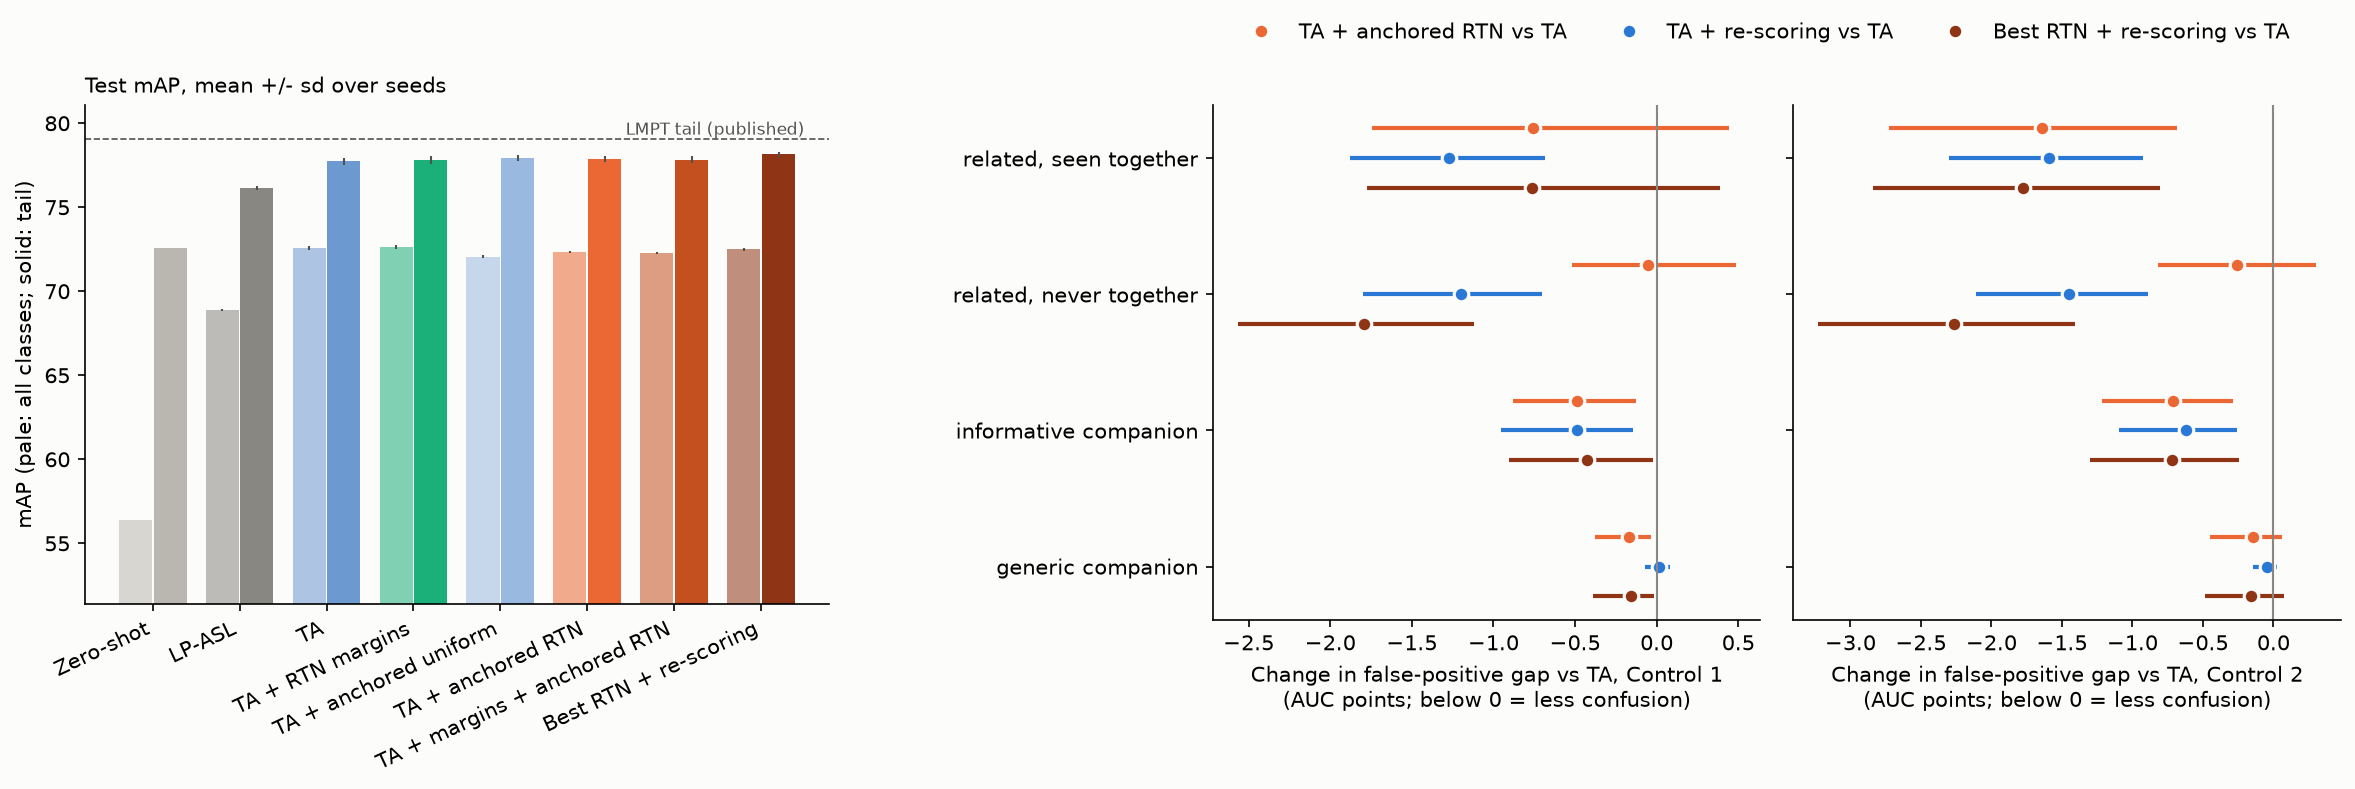

Saved coco_mlt\round5\round5.png


In [14]:
SURFACE, MUTED, INK = "#fcfcfb", "#898781", "#52514e"
COL = {"zs": "#b9b7b0", "lp_asl": MUTED, "ta": "#6c99d0", "margin": "#1baf7a",
       "ca_uni": "#9ab9e0", "ca_rtn": "#eb6834", "ca_margin": "#c4501f",
       "ta_rs": "#2a78d6", "full": "#8f3414"}
FIG_KEYS = ["zs", "lp_asl", "ta", "margin", "ca_uni", "ca_rtn", "ca_margin", "full"]
fig = plt.figure(figsize=(16, 5.2), facecolor=SURFACE)
gs_l = fig.add_gridspec(1, 1, left=0.05, right=0.36, bottom=0.22, top=0.86)
gs_r = fig.add_gridspec(1, 2, left=0.52, right=0.99, bottom=0.2, top=0.86, wspace=0.06)
ax0 = fig.add_subplot(gs_l[0])
x = np.arange(len(FIG_KEYS))
for off, g, alpha in ((-0.2, "all", 0.55), (0.2, "tail", 1.0)):
    vals = [[group_map(a, g) for a in AP_SEED[k]] for k in FIG_KEYS]
    ax0.bar(x + off, [np.mean(v) for v in vals], width=0.38, alpha=alpha,
            color=[COL[k] for k in FIG_KEYS],
            yerr=[np.std(v, ddof=1) if len(v) > 1 else 0 for v in vals],
            error_kw=dict(ecolor=INK, lw=1), label=f"{g} mAP")
ax0.set_xticks(x)
ax0.set_xticklabels([SHORT[k] for k in FIG_KEYS], rotation=25, ha="right")
lo = min(group_map(a, g) for k in FIG_KEYS for a in AP_SEED[k] for g in ("all", "tail"))
hi = max(group_map(a, g) for k in FIG_KEYS for a in AP_SEED[k] for g in ("all", "tail"))
ymin = max(0, lo - 5)
if ymin < 79.08:   # published LMPT tail mAP, for reference
    ax0.axhline(79.08, color=INK, lw=0.8, ls="--")
    ax0.text(len(FIG_KEYS) - 0.5, 79.08, "LMPT tail (published)", fontsize=8,
             color=INK, ha="right", va="bottom")
    ax0.set_ylim(ymin, max(hi, 79.08) + 2)
else:
    ax0.set_ylim(ymin, None)
ax0.set_ylabel("mAP (pale: all classes; solid: tail)")
ax0.set_title("Test mAP, mean +/- sd over seeds", loc="left", fontsize=10)
ax1 = fig.add_subplot(gs_r[0])
ax2 = fig.add_subplot(gs_r[1], sharey=ax1)
ax2.tick_params(labelleft=False)
ty = np.arange(len(TYPES))[::-1]
for i, ax in enumerate((ax1, ax2)):
    for off, (a, b) in zip((0.22, 0.0, -0.22), (("ca_rtn", "ta"), ("ta_rs", "ta"), ("full", "ta"))):
        for j in range(len(TYPES)):
            m, l_, h, _ = TYPE_CI[(a, b, i, j)]
            if not np.isfinite(m):
                continue
            ax.hlines(ty[j] + off, l_, h, color=COL[a], lw=2)
            ax.plot(m, ty[j] + off, "o", color=COL[a], ms=7, mec=SURFACE, mew=1.5,
                    label=f"{SHORT[a]} vs TA" if j == 0 else None)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_xlabel(f"Change in false-positive gap vs TA, Control {i + 1}\n"
                  f"(AUC points; below 0 = less confusion)")
ax1.set_yticks(ty)
ax1.set_yticklabels(TYPES)
h_, l_ = ax1.get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, loc="upper center", bbox_to_anchor=(0.75, 0.99), ncol=3)
for a in (ax0, ax1, ax2):
    a.set_facecolor(SURFACE)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
FIG = os.path.join(OUT, "round5.png")
fig.savefig(FIG, dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.close(fig)
display(Image(filename=FIG))
print(f"Saved {FIG}")

## Step 13: save the results

In [15]:
results_table.to_csv(os.path.join(OUT, "results_round5.csv"), index=False)
raw_table.to_csv(os.path.join(OUT, "results_round5_no_ensemble.csv"), index=False)
cv_table.to_csv(os.path.join(OUT, "cv_round5.csv"), index=False)
rs_table.to_csv(os.path.join(OUT, "rescoring_round5.csv"), index=False)
headroom_table.to_csv(os.path.join(OUT, "headroom_round5.csv"), index=False)
comparisons.to_csv(os.path.join(OUT, "comparisons_round5.csv"), index=False)
gap_levels.to_csv(os.path.join(OUT, "gaps_round5.csv"), index=False)
type_changes.to_csv(os.path.join(OUT, "by_type_round5.csv"), index=False)
pd.DataFrame({NAME[k]: AP[k] for k in KEYS}, index=names).to_csv(
    os.path.join(OUT, "per_class_ap_round5.csv"))
with open(os.path.join(OUT, "summary_round5.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n\n" + results_table.to_string(index=False) + "\n\n"
            + headroom_table.to_string(index=False) + "\n")
print("\n".join(lines))
print(f"\nSaved the tables and summary_round5.txt to {os.path.abspath(OUT)}")

TA + relation-typed class-anchored contrast (ours) vs TA + class-anchored contrast, uniform weights: NOT SHOWN  (tail AP -0.05 [-0.41, +0.20], higher in 3 of 10 seeds; gap reduced under both controls: False; head AP +0.49; overall AP +0.28 [+0.12, +0.42])
TA + relation-typed class-anchored contrast (ours) vs CLIP-initialised adapter (TA): NOT SHOWN  (tail AP +0.15 [-0.41, +0.69], higher in 7 of 10 seeds; gap reduced under both controls: False; head AP -0.40; overall AP -0.24 [-0.52, +0.05])
TA + margins + relation-typed class-anchored contrast (ours) vs CLIP-initialised adapter (TA): NOT SHOWN  (tail AP +0.09 [-0.57, +0.73], higher in 6 of 10 seeds; gap reduced under both controls: False; head AP -0.38; overall AP -0.29 [-0.60, +0.01])
TA + relation-typed re-scoring (ours) vs CLIP-initialised adapter (TA): WORKS  (tail AP +0.49 [+0.20, +0.87], higher in 10 of 10 seeds; gap reduced under both controls: True; head AP +0.00; overall AP +0.29 [+0.07, +0.50])
Best RTN model + re-scoring (ou

## How to read the results

- **Headroom (Step 9)** says how much tail mAP related-class confusion
  costs at most. If it is small, no relation-aware fix can add much
  mAP on COCO-MLT; if it is large, the gap between it and what the
  RTN variants achieve is room still to win.
- **Anchored RTN vs anchored uniform** tests the relation types inside
  the class-anchored contrast; **vs TA** shows what the contrastive
  loss adds at all.
- **Best RTN + re-scoring vs TA** is the complete relation-typed
  system against the same model without relation types.
- The by-type table shows whether each variant reduces the confusion
  it targets (related classes) and leaves the others alone.

## Limitations

- Round 5 was designed after seeing rounds 3-4, so its verdicts are
  exploratory; a gain must be confirmed on a second dataset (VOC-MLT)
  with every setting fixed in advance.
- Settings and re-scoring strengths are chosen by cross-validation
  with one seed; variants with more settings can look optimistic in
  cross-validation but not on the test images.
- The headroom replaces scores with those of unrelated negatives with
  the same number of objects; it bounds what removing this confusion
  could give, not what a particular method will give.